# Modeling Human Activity States with Hidden Markov Models

**Use case:** elderly fall-risk and inactivity monitoring.

This notebook covers data loading, pre-processing and 25 Hz harmonisation, a fixed recording-level
train/test split, feature extraction with training-only normalisation, a from-scratch NumPy HMM with
mathematical verification, model training, held-out evaluation, and decoding of continuous sessions.
Jumping stands in for an impact activity; it is not fall data.

Run all cells from top to bottom; every path is relative to the repository root.

## 1. Setup & Data Loading

Recordings were made with **Sensor Logger** (Android, Infinix X6855). Each export is a folder with one CSV per sensor. Each CSV has `time` (ns since the Unix epoch), `seconds_elapsed`, and the axes in the order `z, y, x`. A `Metadata.csv` file records the device and the configured sample rates.

Two streams are used:

| Stream | File | Units | Why |
|---|---|---|---|
| Accelerometer | `TotalAcceleration.csv` | m/s² | The true accelerometer reading, **including gravity**. The app's `Accelerometer.csv` has gravity removed, which would discard the orientation cue that separates *still* (phone flat) from *standing* (phone upright). |
| Gyroscope | `Gyroscope.csv` | rad/s | Calibrated angular velocity (bias-corrected). |

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if not (ROOT / "Plan.md").exists():
    raise RuntimeError("Start Jupyter from the repository root or notebooks directory")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
RAW_DIR = ROOT / "data/raw"
PROCESSED_DIR = ROOT / "data/processed"
LABELS_DIR = ROOT / "data/labels"
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 3)

### 1.1 Loading utilities

The reusable implementation is in `scripts/preprocessing.py`. It is shared with
the command-line pipeline and regression checks, so the notebook and exported
CSVs use the same cleaning rules. Raw exports remain unchanged. Timestamps are
sorted; exact duplicate samples are counted and removed. Conflicting duplicates,
non-finite readings, and malformed timestamps fail validation.

In [2]:
from scripts.preprocessing import (
    ACTIVITIES, SENSOR_FILES, TARGET_FS, SIGNALS,
    load_metadata, load_sensor, load_recording, sampling_stats,
    gap_intervals, harmonise_recording, trim_clip, label_session,
    save_processed, build_dataset, require_training_ready, load_labelled_sequences,
)

### 1.2 Pilot check

Before the main collection, four short pilot recordings were made to check the data format:

| Pilot | Phone | Question it answers |
|---|---|---|
| `pilot_01_flat` | Flat on a table | Is gravity included? Which axis carries it when flat? |
| `pilot_02_upright` | Held at waist level (the grip used for standing, walking, jumping) | Which axis carries gravity when upright? |
| `pilot_03_walk` | Same grip, walking | Data quality during movement |
| `pilot_04_flat_50hz` | Flat, app set to a lower rate | Does the rate setting change the delivered rate? |

In [3]:
pilots = [load_recording(p) for p in sorted((RAW_DIR / "pilot").iterdir()) if p.is_dir()]

print(f"Device: {pilots[0]['meta']['device']}  |  {pilots[0]['meta']['platform']}  |  Sensor Logger {pilots[0]['meta']['app_version']}")
pilot_rates = pd.DataFrame([
    {"recording": rec["name"], "sensor": sensor,
     "configured_hz": rec["meta"]["configured_hz"][sensor], **sampling_stats(rec[sensor])}
    for rec in pilots for sensor in SENSOR_FILES
]).set_index(["recording", "sensor"])
pilot_rates

Device: Infinix X6855  |  android 36  |  Sensor Logger 1.68


configured_hz  n_samples  duration_s  measured_hz  \
recording          sensor                                                      
pilot_01_flat      acc             100.0        574       9.804       58.445   
                   gyro            100.0        575       9.825       58.445   
pilot_02_upright   acc             100.0        736      12.575       58.448   
                   gyro            100.0        739      12.635       58.448   
pilot_03_walk      acc             100.0        898      15.342       58.452   
                   gyro            100.0        897      15.329       58.452   
pilot_04_flat_50hz acc              50.0        528      18.031       29.227   
                   gyro             50.0        529      18.066       29.227   

                           median_dt_ms  jitter_ms  normal_interval_jitter_ms  \
recording          sensor                                                       
pilot_01_flat      acc           17.110  1.517e-04                  1.517e-04   
                   gyro          17.110  1.784e-01                  1.784e-01   
pilot_02_upright   acc           17.109  1.330e-04                  1.330e-04   
                   gyro          17.109  3.147e-01                  3.147e-01   
pilot_03_walk      acc           17.108  1.427e-01                  1.427e-01   
                   gyro          17.108  1.627e-04                  1.627e-04   
pilot_04_flat_50hz acc           34.215  1.718e-04                  1.718e-04   
                   gyro          34.215  1.809e-04                  1.809e-04   

                           max_dt_ms  dropped  large_gaps  duplicates_removed  
recording          sensor                                                      
pilot_01_flat      acc        17.110        0           0                   0  
                   gyro       21.387        0           0                   0  
pilot_02_upright   acc        17.110        0           0                   0  
                   gyro       25.664        0           0                   0  
pilot_03_walk      acc        17.109        0           0                   0  
                   gyro       17.109        0           0                   0  
pilot_04_flat_50hz acc        34.216        0           0                   0  
                   gyro       34.216        0           0                   0

In [4]:
def stream_offset_ms(rec):
    """Start-time difference between the gyroscope and accelerometer streams (ms)."""
    return (rec["gyro"]["t"].iloc[0] - rec["acc"]["t"].iloc[0]) * 1e3


def shared_timestamps(rec):
    """Fraction of accelerometer timestamps that also appear in the gyroscope stream."""
    return np.isin(rec["acc"]["timestamp_ns"], rec["gyro"]["timestamp_ns"]).mean()


pd.DataFrame([
    {"recording": rec["name"], "gyro_start_offset_ms": stream_offset_ms(rec),
     "shared_timestamps": shared_timestamps(rec)}
    for rec in pilots
]).set_index("recording")

,gyro_start_offset_ms,shared_timestamps
recording,,
pilot_01_flat,-17.110,0.0
pilot_02_upright,-17.109,0.0
pilot_03_walk,17.108,0.0
pilot_04_flat_50hz,-17.108,0.0


In [5]:
def steady(df, trim_s=1.0):
    """Drop the first and last trim_s seconds (button-press and settling artefacts)."""
    t = df["t"]
    return df[(t > t.iloc[0] + trim_s) & (t < t.iloc[-1] - trim_s)]


def magnitude(df):
    """Euclidean norm of the x, y, z columns."""
    return np.sqrt(df["x"] ** 2 + df["y"] ** 2 + df["z"] ** 2)


orientation = pd.DataFrame([
    {"recording": rec["name"],
     **{f"mean_acc_{ax}": steady(rec["acc"])[ax].mean() for ax in "xyz"},
     "mean_|a|": magnitude(steady(rec["acc"])).mean(),
     "std_|a|": magnitude(steady(rec["acc"])).std(),
     "std_|w|": magnitude(steady(rec["gyro"])).std()}
    for rec in pilots
]).set_index("recording")
orientation

,mean_acc_x,mean_acc_y,mean_acc_z,mean_|a|,std_|a|,std_|w|
recording,,,,,,
pilot_01_flat,-0.081,0.578,9.819,9.836,0.007,4.311e-04
pilot_02_upright,0.369,9.843,1.286,9.944,0.142,1.044e-01
pilot_03_walk,0.299,9.857,1.094,9.992,0.852,4.798e-01
pilot_04_flat_50hz,-0.137,0.502,9.826,9.840,0.048,6.309e-03


### 1.3 Pilot findings

- `TotalAcceleration` contains gravity: flat-on-table z is approximately 9.8 m/s²;
  the waist-level pilot places most gravity on y. This makes orientation a useful
  cue under this collection protocol, not proof of generalisation to other grips.
- The 100 Hz setting delivers approximately 58.4 Hz and the 50 Hz setting delivers
  approximately 29.2 Hz. These are measured results for this device; they do not
  establish the cause of the app/hardware rate difference.
- Pilot jitter reaches approximately 0.315 ms, with no intervals above three times
  the median. These pilot findings must not be extended to the training sessions.
- Sensors have offset sampling instants and no shared timestamps in these pilots.
  This does not by itself imply separate hardware clocks.
- A common 25 Hz grid avoids upsampling either source. Its 12.5 Hz Nyquist covers
  the observed activity fundamentals; a 10 Hz low-pass filter attenuates higher
  frequencies, including some impact detail. The filter is not an ideal brick wall.

## 2. Pre-processing & Sampling-Rate Harmonisation

Each native stream is filtered using a fourth-order, zero-phase Butterworth
low-pass at 10 Hz (implemented as second-order sections for numerical stability).
Both filtered streams are interpolated **once** onto the same integer-nanosecond
25 Hz grid, restricted to shared coverage.

Intervals exceeding three times the median sampling interval split a session **before filtering**. The union of both sensors' gaps defines independent blocks. Blocks shorter than seven seconds are discarded; one second is trimmed from both ends of each remaining block after filtering. No values, durations or transitions are inferred across an outage. A whole-recording resampling request still rejects gaps.

**No-re-recording decision (29 Oct):** keep 52 labelled clips and recover continuous session blocks without labels. The participant has no session footage or exact timer records; roughly 15-second timing cannot verify boundaries. The original session labels remain provisional and do not enter supervised training. Phase 4 now reserves eight single-activity clips for testing; only the other 44 may initialise supervised emissions. Phone orientation is retained as recorded, including the different session-1 grip. Two labelled training sessions were a plan choice; two unseen test files remain required later.

Clips retain at least one second of exclusion at each end. Reviewed signal-based
crop intervals in `data/clip_intervals.csv` remove additional quiet lead-ins and
handling artifacts and cap each clip at 10 seconds. SHA-256 fingerprints bind
these decisions to the recordings inspected. Original single-activity labels are
retained.

`timestamp_ns` is always Unix epoch nanoseconds. `seconds_elapsed` is always
relative to the **original recording start**, including after cropping; it need
not start at zero. Crop offsets remain traceable to the original data.

### 2.1 Build and validate the available dataset

The pipeline regenerates metadata (including pilots), sampling/gap reports, valid
processed files, independent unlabelled session blocks, crop provenance and `data/quality/status.json`. It removes stale
CSV files from its generated training output directories. Raw recordings and
original session labels remain untouched.

Sessions have only an approximate timer schedule, so they never become labelled
data: the pipeline exports their unbroken blocks without labels.

In [6]:
result = build_dataset(ROOT, output_dir=PROCESSED_DIR)
all_recs = [r for r in result["records"] if r["rec_type"] in ("clip", "session")]
clips = [r for r in all_recs if r["rec_type"] == "clip"]
sessions = [r for r in all_recs if r["rec_type"] == "session"]
processed_clips = [r for r in result["accepted"] if r["rec_type"] == "clip"]
processed_sessions = [r for r in result["accepted"] if r["rec_type"] == "session"]
training_clips = [r for r in processed_clips if r["split"] == "train"]
test_clips = [r for r in processed_clips if r["split"] == "test"]
qdf = result["quality"]
print(f"Accepted {len(processed_clips)}/52 clips; {len(processed_sessions)} verified labelled sessions; {len(result['unlabelled'])} unlabelled session blocks")
display(result["rejected"][["recording", "reason"]] if not result["rejected"].empty else "No rejected recordings")
print(f"Fixed split: {len(training_clips)} training clips; {len(test_clips)} held-out test clips")

Accepted 52/52 clips; 0 verified labelled sessions; 4 unlabelled session blocks


,recording,reason
0,train_session_01,acc: 2 large gaps (max 6.544s); gyro: 2 large ...
1,train_session_02,acc: 2 large gaps (max 87.533s); gyro: 2 large...


Fixed split: 44 training clips; 8 held-out test clips


### 2.2 Sampling quality and report table

The following table is computed from **every stream**, not entered by hand. Full
jitter includes gaps. Normal-interval jitter is a separate diagnostic, never a
replacement for reporting outages. `duration_s` is timestamp span, which can
include missing time; only accepted clips contribute to the duration requirement.

In [7]:
rate_table = qdf[["recording", "type", "sensor", "configured_hz", "measured_hz",
                  "duration_s", "jitter_ms", "normal_interval_jitter_ms",
                  "max_dt_ms", "large_gaps", "duplicates_removed"]].copy()
accepted_names = {r["name"] for r in result["accepted"]}
rate_table["split"] = rate_table.recording.map({r["name"]: r["split"] for r in result["records"]})
rate_table["harmonised_hz"] = np.where(rate_table.recording.isin(accepted_names), TARGET_FS, np.nan)
rate_table["disposition"] = np.where(rate_table.recording.isin(accepted_names), "accepted",
                                   np.where(rate_table.type == "pilot", "pilot only", "excluded"))
rate_table.to_csv(ROOT / "data/quality/sampling_rate_report.csv", index=False)
display(rate_table)
display(pd.read_csv(ROOT / "data/quality/gaps.csv"))

,recording,type,sensor,configured_hz,measured_hz,duration_s,jitter_ms,normal_interval_jitter_ms,max_dt_ms,large_gaps,duplicates_removed,split,harmonised_hz,disposition
0,jumping_01,clip,acc,100.0,58.446,12.815,1.567e-04,1.567e-04,17.110,0,0,train,25.0,accepted
1,jumping_01,clip,gyro,100.0,58.446,12.837,1.561e-01,1.561e-01,21.387,0,0,train,25.0,accepted
2,jumping_02,clip,acc,100.0,58.446,12.028,1.508e-04,1.508e-04,17.110,0,0,test,25.0,accepted
3,jumping_02,clip,gyro,100.0,58.446,12.028,1.530e-04,1.530e-04,17.110,0,0,test,25.0,accepted
4,jumping_03,clip,acc,100.0,58.447,10.330,1.739e-01,1.739e-01,17.110,0,0,train,25.0,accepted
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
111,pilot_04_flat_50hz,pilot,gyro,50.0,29.227,18.066,1.809e-04,1.809e-04,34.216,0,0,pilot,NaN,pilot only
112,train_session_01,session,acc,100.0,58.455,137.782,9.446e+01,1.895e-04,6543.599,2,0,train,NaN,excluded
113,train_session_01,session,gyro,100.0,58.455,137.791,9.447e+01,1.113e-01,6560.707,2,0,train,NaN,excluded
114,train_session_02,session,acc,100.0,58.454,114.019,2.225e+03,1.660e-04,87532.872,2,0,train,NaN,excluded


,recording,sensor,start_s,end_s,gap_s
0,train_session_01,acc,44.978,49.828,4.850
1,train_session_01,acc,79.646,86.190,6.544
2,train_session_01,gyro,44.987,49.815,4.829
3,train_session_01,gyro,79.637,86.198,6.561
4,train_session_02,acc,0.057,0.129,0.073
5,train_session_02,acc,25.397,112.930,87.533
6,train_session_02,gyro,0.044,0.108,0.064
7,train_session_02,gyro,25.401,112.917,87.516


### 2.3 Verify both native rates against the common grid

Pilots at both settings exercise the same filter and resampling code without
becoming training data. Integer timestamp differences must be exactly 40,000,000 ns.

In [8]:
for rec in pilots:
    aligned = harmonise_recording(rec)
    assert np.all(np.diff(aligned.timestamp_ns) == 40_000_000)
    assert np.isfinite(aligned[SIGNALS]).all().all()
    print(f"{rec['name']}: configured {rec['meta']['configured_hz']['acc']:.0f} Hz, "
          f"measured {sampling_stats(rec['acc'])['measured_hz']:.3f} Hz -> {TARGET_FS} Hz")

pilot_01_flat: configured 100 Hz, measured 58.445 Hz -> 25 Hz
pilot_02_upright: configured 100 Hz, measured 58.448 Hz -> 25 Hz
pilot_03_walk: configured 100 Hz, measured 58.452 Hz -> 25 Hz
pilot_04_flat_50hz: configured 50 Hz, measured 29.227 Hz -> 25 Hz


### 2.4 Check every processed clip and activity duration

Duration is conservatively measured as last minus first timestamp. Sessions,
including interpolated or unverified time, do not contribute to the ≥90 s check.

In [9]:
crop_summary = result["crops"].groupby("activity").agg(
    files=("file", "size"), min_s=("duration_s", "min"),
    max_s=("duration_s", "max"), total_s=("duration_s", "sum"))
display(crop_summary)
assert len(processed_clips) == 52, "Expected all 52 accepted clips"
assert (crop_summary.files == 13).all()
assert result["crops"].duration_s.between(5, 10).all()
assert (crop_summary.total_s >= 90).all()
for rec in processed_clips:
    folder = "train/clips" if rec["split"] == "train" else "test"
    saved = pd.read_csv(PROCESSED_DIR / folder / f"{rec['name']}.csv")
    assert np.isfinite(saved.select_dtypes("number")).all().all()
    assert np.all(np.diff(saved.timestamp_ns) == 40_000_000)
    raw_rec = next(r for r in clips if r["name"] == rec["name"])
    np.testing.assert_allclose((saved.timestamp_ns.to_numpy() - raw_rec["meta"]["epoch_ns"]) / 1e9,
                               saved.seconds_elapsed, atol=1e-9, rtol=0)
print("PASS: all 52 CSVs satisfy duration, class count, finite-value, and timestamp checks")

,files,min_s,max_s,total_s
activity,,,,
jumping,13,5.96,9.96,99.92
standing,13,5.96,10.00,119.84
still,13,10.00,10.00,130.00
walking,13,5.12,10.00,112.72


PASS: all 52 CSVs satisfy duration, class count, finite-value, and timestamp checks


### 2.5 Raw-data figure for the report

These are **unfiltered native measurements** over each selected clip interval.
Acceleration and angular velocity have distinct scales and labelled units; time
is shifted to the crop start for plotting only. The CSVs preserve recording time.

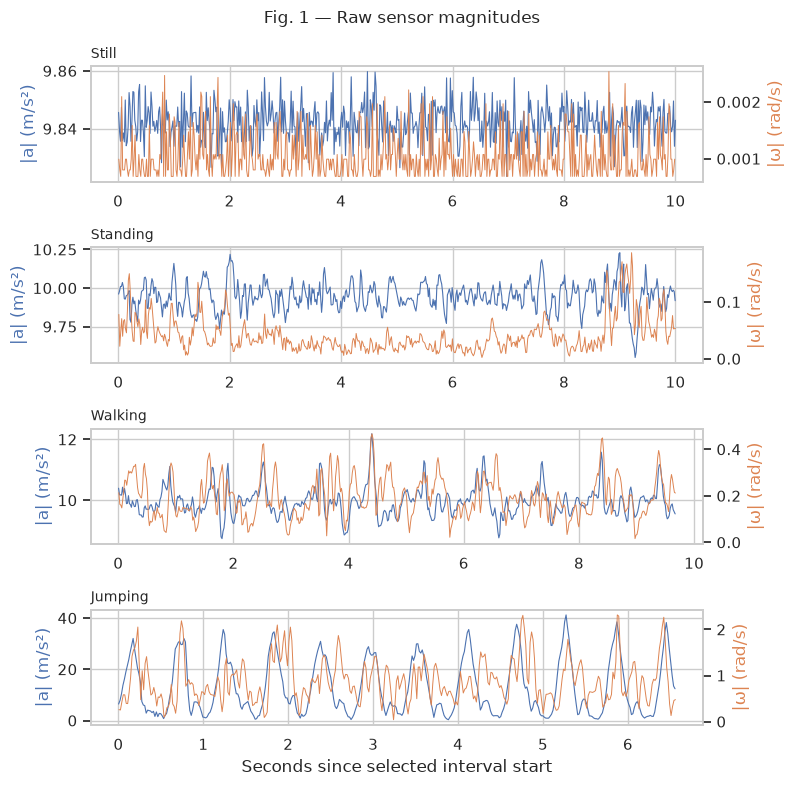

In [10]:
rep_clips = {"still": "still_03", "standing": "standing_03",
             "walking": "walking_03", "jumping": "jumping_03"}

def raw_crop(name, sensor):
    rec = next(r for r in clips if r["name"] == name)
    bounds = result["crops"].set_index("file").loc[name]
    df = rec[sensor]
    return df[df.t.between(bounds.start_s, bounds.end_s)], bounds.start_s

fig, axes = plt.subplots(4, 1, figsize=(8, 8))
for ax, activity in zip(axes, ACTIVITIES):
    acc, origin = raw_crop(rep_clips[activity], "acc")
    gyro, _ = raw_crop(rep_clips[activity], "gyro")
    second = ax.twinx()
    ax.plot(acc.t - origin, np.linalg.norm(acc[["x", "y", "z"]], axis=1), color="C0", lw=.8)
    second.plot(gyro.t - origin, np.linalg.norm(gyro[["x", "y", "z"]], axis=1), color="C1", lw=.7)
    ax.set_ylabel("|a| (m/s²)", color="C0")
    second.set_ylabel("|ω| (rad/s)", color="C1")
    second.grid(False)
    ax.set_title(activity.capitalize(), loc="left", fontsize=10)
axes[-1].set_xlabel("Seconds since selected interval start")
fig.suptitle("Fig. 1 — Raw sensor magnitudes", fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig1_raw_signals.png", dpi=200, bbox_inches="tight")
plt.show()

### 2.6 All six native axes, by activity (notebook only)

Gravity orientation distinguishes the collection setups. This cue depends on
holding the phone consistently and should be discussed as a limitation.

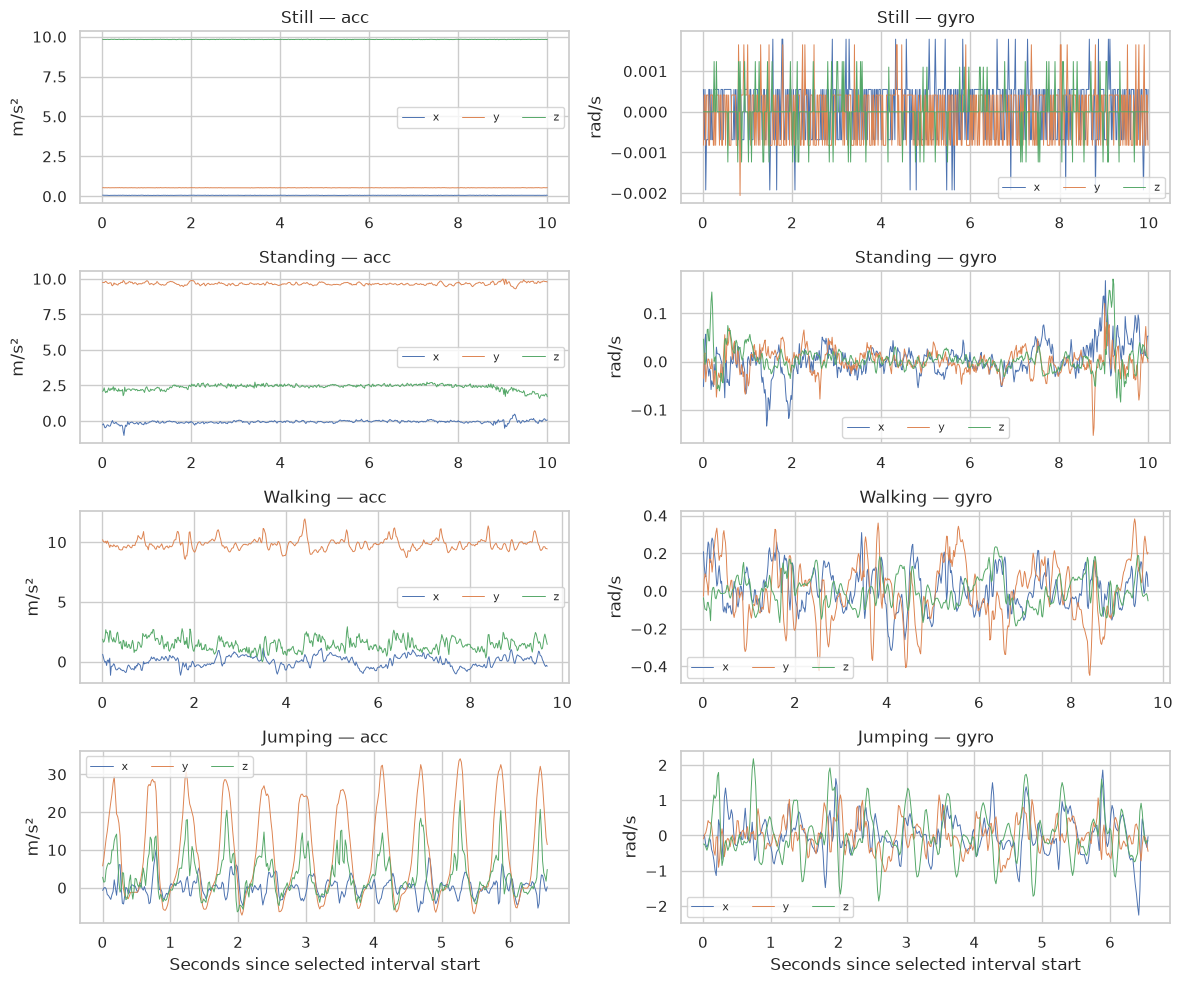

In [11]:
fig, axes = plt.subplots(4, 2, figsize=(12, 10))
for i, activity in enumerate(ACTIVITIES):
    for j, sensor in enumerate(SENSOR_FILES):
        df, origin = raw_crop(rep_clips[activity], sensor)
        for axis in "xyz":
            axes[i, j].plot(df.t - origin, df[axis], label=axis, lw=.7)
        axes[i, j].set_title(f"{activity.capitalize()} — {sensor}")
        axes[i, j].set_ylabel("m/s²" if sensor == "acc" else "rad/s")
        axes[i, j].legend(ncol=3, fontsize=8)
for ax in axes[-1]: ax.set_xlabel("Seconds since selected interval start")
fig.tight_layout()
plt.show()

### 2.7 Sampling interval and retained-duration plots (notebook only)

The histogram covers both sensors in **all 52 clips**. Session outages are listed
separately above rather than hidden in a narrow histogram. Plot bins are fixed
in milliseconds so floating-point noise cannot exaggerate tiny timing changes.

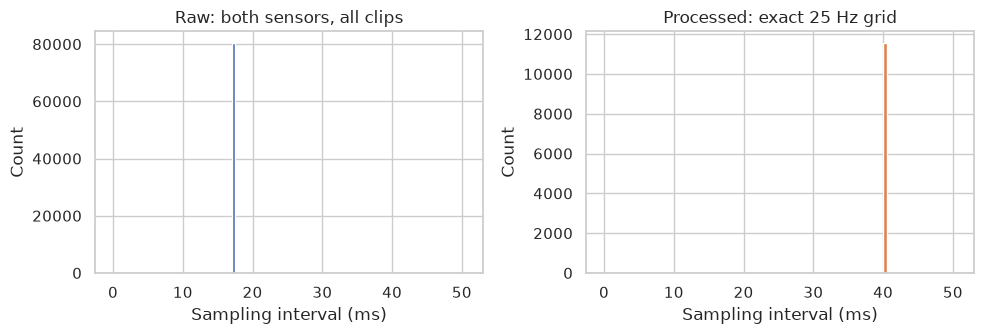

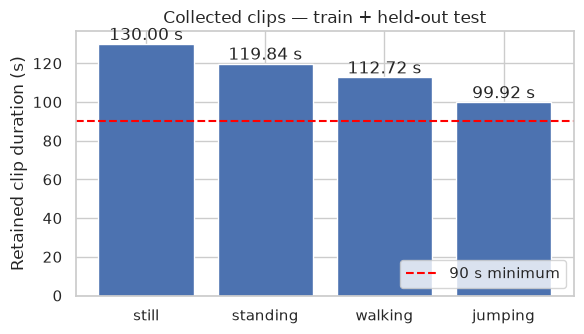

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
raw_dt = np.concatenate([np.diff(r[s].timestamp_ns.to_numpy()) / 1e6 for r in clips for s in SENSOR_FILES])
new_dt = np.concatenate([np.diff(r["df"].timestamp_ns.to_numpy()) / 1e6 for r in processed_clips])
axes[0].hist(raw_dt, bins=np.arange(0, 51, .5), color="C0")
axes[1].hist(new_dt, bins=np.arange(0, 51, .5), color="C1")
for ax, title in zip(axes, ["Raw: both sensors, all clips", "Processed: exact 25 Hz grid"]):
    ax.set(title=title, xlabel="Sampling interval (ms)", ylabel="Count")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 3.5))
values = [result["status"]["clip_seconds_per_activity"][a] for a in ACTIVITIES]
bars = ax.bar(ACTIVITIES, values)
ax.axhline(90, color="red", ls="--", label="90 s minimum")
ax.bar_label(bars, fmt="%.2f s")
ax.set(ylabel="Retained clip duration (s)", title="Collected clips — train + held-out test")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

### 2.8 Session diagnostics and label review (notebook only)

These figures show **raw session diagnostics, not supervised ground truth**. Dark spans are
missing data; lines break at outages. Existing label boundaries are provisional,
not independently verified truth. No session shown here is automatically admitted
by inspecting its plot. Session 1's walking onset and changed orientation need
recording evidence that is unavailable; session 2 is largely missing and has no segment table. Only continuous portions are retained, without labels.

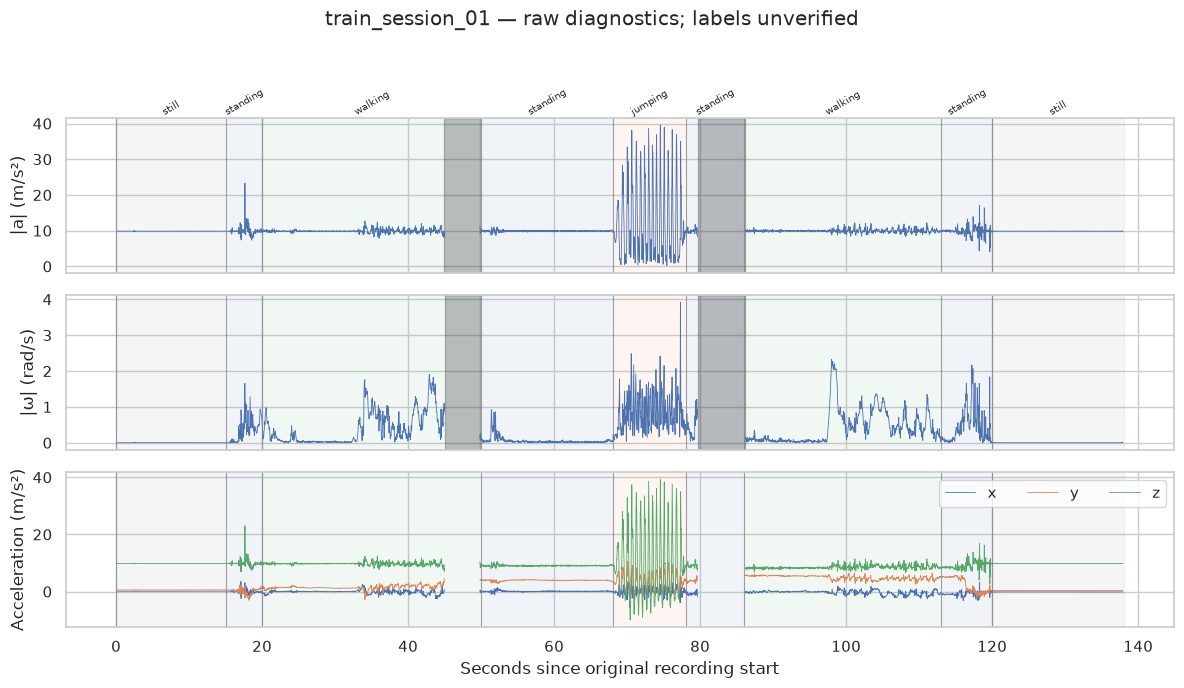

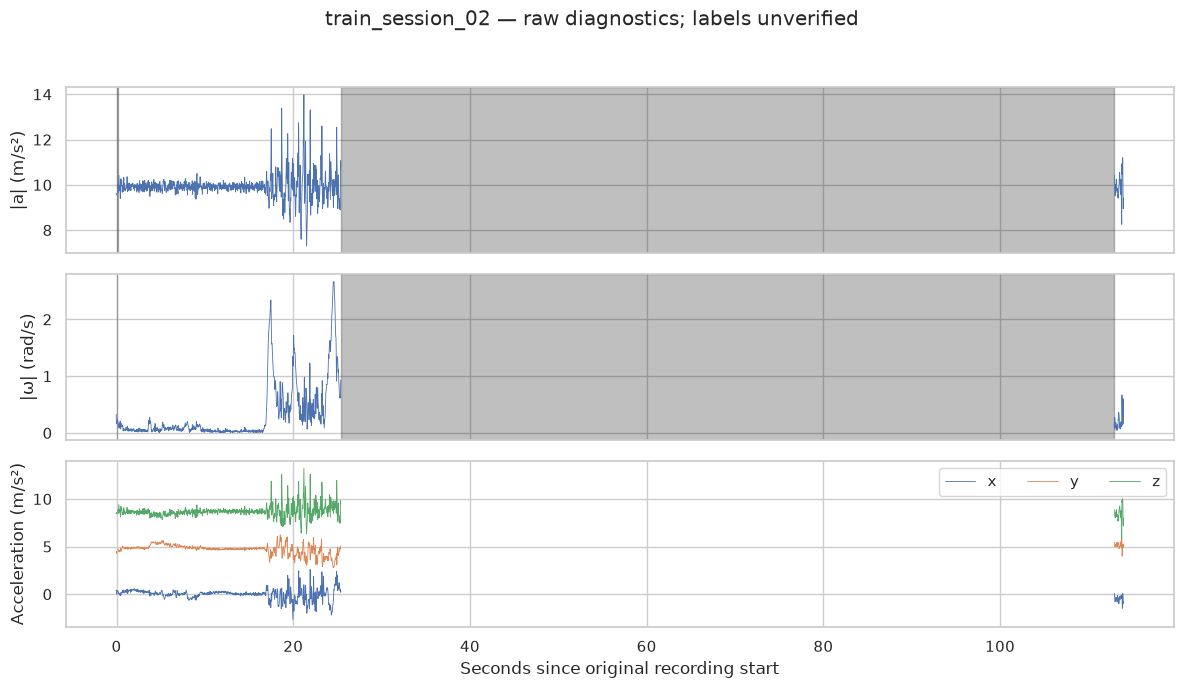

,recording,start_s,activity,mean_acc_x,mean_acc_y,mean_acc_z
0,train_session_01,0.0,still,0.123,0.569,9.824
1,train_session_01,15.0,standing,0.050,0.191,9.847
2,train_session_01,20.0,walking,-0.111,1.511,9.715
3,train_session_01,50.0,standing,0.097,3.928,9.082
4,train_session_01,68.0,jumping,0.179,3.087,9.296
5,train_session_01,78.0,standing,-0.753,3.723,9.077
6,train_session_01,86.0,walking,-0.304,4.936,8.557
7,train_session_01,113.0,standing,-0.728,2.413,9.148
8,train_session_01,120.0,still,-0.130,0.390,9.831


Compare standing clips (mean gravity predominantly on y) with the rejected session's z-dominant grip.


In [13]:
colours = {"still": "grey", "standing": "C0", "walking": "C2", "jumping": "C1"}
orientation_rows = []
for rec in sessions:
    fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
    for i, sensor in enumerate(SENSOR_FILES):
        df = rec[sensor]
        values = np.linalg.norm(df[["x", "y", "z"]], axis=1)
        gap_indices = np.flatnonzero(np.diff(df.timestamp_ns) > 3 * np.median(np.diff(df.timestamp_ns)))
        values[gap_indices] = np.nan
        axes[i].plot(df.t, values, lw=.6)
        axes[i].set_ylabel("|a| (m/s²)" if sensor == "acc" else "|ω| (rad/s)")
        for gap in gap_intervals(df):
            axes[i].axvspan(gap["start_s"], gap["end_s"], color="black", alpha=.25)
    df = rec["acc"]
    for axis in "xyz":
        values = df[axis].to_numpy().copy()
        values[np.flatnonzero(np.diff(df.timestamp_ns) > 3 * np.median(np.diff(df.timestamp_ns)))] = np.nan
        axes[2].plot(df.t, values, label=axis, lw=.6)
    axes[2].set_ylabel("Acceleration (m/s²)")
    axes[2].legend(ncol=3)
    label_path = LABELS_DIR / f"{rec['name']}.csv"
    if label_path.exists():
        for seg in pd.read_csv(label_path).itertuples():
            for ax in axes:
                ax.axvspan(seg.start_s, seg.end_s, color=colours[seg.activity], alpha=.08)
                ax.axvline(seg.start_s, color="grey", lw=.5)
            axes[0].text((seg.start_s+seg.end_s)/2, 1.02, seg.activity,
                         transform=axes[0].get_xaxis_transform(), ha="center", fontsize=7, rotation=30)
            selected = df[df.t.between(seg.start_s, seg.end_s, inclusive="left")]
            orientation_rows.append({"recording": rec["name"], "start_s": seg.start_s,
                                     "activity": seg.activity, **{f"mean_acc_{a}": selected[a].mean() for a in "xyz"}})
    axes[-1].set_xlabel("Seconds since original recording start")
    fig.suptitle(f"{rec['name']} — raw diagnostics; labels unverified")
    fig.tight_layout(rect=[0, 0, 1, .95])
    fig.savefig(FIG_DIR / f"{rec['name']}_quality.png", dpi=150)
    plt.show()
display(pd.DataFrame(orientation_rows))
print("Compare standing clips (mean gravity predominantly on y) with the rejected session's z-dominant grip.")

### 2.9 Recoverable session blocks

Each file below preserves its original timestamp origin, has exact 25 Hz spacing,
and was filtered independently. The CSV schema deliberately omits `activity`.
Approximate original labels remain only in `data/labels/` for diagnostics. Source
fingerprints and the retained bounds are saved in the sequence manifest.
The shifted phone orientation is a distribution difference to discuss, not a
reason to invent an axis transformation or claim these recordings are equivalent
to the fixed-grip clips.

In [14]:
display(result["block_manifest"])
for block in result["unlabelled"]:
    df = pd.read_csv(PROCESSED_DIR / "unlabelled/sessions" / f"{block['name']}.csv")
    assert "activity" not in df.columns
    assert np.all(np.diff(df.timestamp_ns) == 40_000_000)
    assert np.isfinite(df.select_dtypes("number")).all().all()
print("PASS — no labels or cross-gap continuity are fabricated")

,sequence,recording,start_s,end_s,duration_s,n_samples,source_sha256,label_status
0,train_session_01_part01,train_session_01,1.131,43.931,42.80,1071,bc523de5635f7944705fd9b7c9354302a1f998b5d143ff...,unverified; no labels exported
1,train_session_01_part02,train_session_01,50.836,78.596,27.76,695,bc523de5635f7944705fd9b7c9354302a1f998b5d143ff...,unverified; no labels exported
2,train_session_01_part03,train_session_01,87.207,136.887,49.68,1243,bc523de5635f7944705fd9b7c9354302a1f998b5d143ff...,unverified; no labels exported
3,train_session_02_part01,train_session_02,1.134,24.374,23.24,582,16ffdc7ec3b61c3adabad31c0b38a88298a7b302f9d0b2...,unverified; no labels exported


PASS — no labels or cross-gap continuity are fabricated


### 2.10 Collection readiness under the revised strategy

The **44 training clips** support supervised emission initialisation. The eight held-out clips must not be used for fitting or tuning. Session activity
boundaries remain unverified, so they must not be used for labelled transition
counts or accuracy metrics. Later HMM work can use an explicit persistence prior
and optionally Baum–Welch on the independent unlabelled blocks. Keep each file
as a separate sequence; never join across gaps or across recordings.

`require_training_ready()` and `python scripts/preprocessing.py --require-complete`
validate all 52 collected clips and the fixed 44-training/8-test partition. Passing
them does **not** certify session ground truth or generalisation beyond the held-out clips.

In [15]:
require_training_ready(result["status"])
print("PASS — labelled clip dataset ready under the revised no-re-recording strategy")
print(f"Optional unlabelled sequences: {len(result['unlabelled'])}")
print("Session ground-truth labels: NOT VERIFIED; exclude from supervised transitions and accuracy")

PASS — labelled clip dataset ready under the revised no-re-recording strategy
Optional unlabelled sequences: 4
Session ground-truth labels: NOT VERIFIED; exclude from supervised transitions and accuracy


## 3. Phase 4 — fixed recording-level holdout

The participant intended the 52 single-activity recordings to supply both training
and test data. Before feature extraction or model fitting, **two entire recordings
per activity** were selected with NumPy's `default_rng(42)`, sampling without
replacement from sorted names in the order still, standing, walking, jumping.
The chosen membership is frozen in `data/split_manifest.csv`; rerunning this
notebook validates it and never selects a new split.

This yields **44 training clips (11 per activity)** and **8 test clips (2 per
activity)**. The collected dataset still has 52 files and at least 90 seconds per
activity; those are collection totals, not training-only totals. Original files
remain in `data/raw/clips/` with their unchanged activity labels. The metadata
and manifest determine membership; directory ancestry alone does not.

The test clips were already inspected and cropped during quality assurance.
Filtering/cropping are now fixed and remain unchanged. No HMM, feature selector,
normaliser, state mapping or hyperparameter search was fitted before this split.
From this point, all learned choices use only the training partition. Use
training-only validation to compare features or models; evaluate the test set at
the end. Do not claim that these clips were untouched by all exploratory work.

The original proposal of two new mixed-activity sessions at different dates and
native rates is replaced by eight independent held-out single-activity files.
They assess recognition within the existing single-person/device collection,
not generalisation to a different day/place or real cross-activity transitions.
Do not join the test clips into a fabricated continuous activity sequence.
All main clips use the configured 100 Hz setting; the lower-rate pilot is a
preprocessing demonstration only, not unseen evaluation data.

In [16]:
manifest = result["split_manifest"]
split_counts = manifest.groupby(["activity", "split"]).size().unstack().reindex(ACTIVITIES)
assert (split_counts["train"] == 11).all()
assert (split_counts["test"] == 2).all()
display(split_counts)
display(manifest.loc[manifest.split == "test", ["activity", "split", "seed"]])
# File-level validation only: no learned statistics or predictions on test data.
training_sequences = load_labelled_sequences(ROOT, "train")
test_sequences = load_labelled_sequences(ROOT, "test")
assert len(training_sequences) == 44 and len(test_sequences) == 8
assert not ({name for name, _ in training_sequences} & {name for name, _ in test_sequences})
print("PASS: fixed 44/8 split; source fingerprints and output membership verified")
print("Keep every file as an independent sequence when windowing and decoding.")

split,test,train
activity,,
still,2,11
standing,2,11
walking,2,11
jumping,2,11


,activity,split,seed
file,,,
still_02,still,test,42
still_11,still,test,42
standing_06,standing,test,42
standing_13,standing,test,42
walking_02,walking,test,42
walking_10,walking,test,42
jumping_02,jumping,test,42
jumping_07,jumping,test,42


PASS: fixed 44/8 split; source fingerprints and output membership verified
Keep every file as an independent sequence when windowing and decoding.


### 3.1 Split provenance and collection conditions

The table records actual dates, location types and rates, without inventing a new
location/day or a lower-rate test acquisition. Unlabelled session blocks belong
only to the optional training pool. Their raw time spans are checked against the
held-out recordings to guard against reuse under another filename.

In [17]:
metadata = pd.read_csv(ROOT / "data/metadata.csv").set_index("file")
test_details = metadata.loc[manifest.index[manifest.split == "test"],
                            ["activity", "date", "location_type", "configured_hz", "measured_acc_hz", "measured_gyro_hz"]]
display(test_details)
display(result["crops"].groupby(["activity", "split"]).agg(
    files=("file", "size"), seconds=("duration_s", "sum")))
assert set(metadata.loc[manifest.index, "split"]) == {"train", "test"}
assert (metadata.loc[manifest.index, "split"] == manifest["split"]).all()
print("Phase 4 complete for the revised held-out-clip design.")
print("The test files are single-activity clips; no continuous-transition test claim is made.")

,activity,date,location_type,configured_hz,measured_acc_hz,measured_gyro_hz
file,,,,,,
still_02,still,2026-10-28,indoor,100.0,58.456,58.456
still_11,still,2026-10-28,indoor,100.0,58.453,58.453
standing_06,standing,2026-10-25,indoor,100.0,58.455,58.455
standing_13,standing,2026-10-27,indoor,100.0,58.439,58.439
walking_02,walking,2026-10-25,indoor,100.0,58.457,58.457
walking_10,walking,2026-10-27,indoor,100.0,58.446,58.446
jumping_02,jumping,2026-10-27,indoor,100.0,58.446,58.446
jumping_07,jumping,2026-10-27,indoor,100.0,58.448,58.448


files  seconds
activity split                
jumping  test       2    13.12
         train     11    86.80
standing test       2    20.00
         train     11    99.84
still    test       2    20.00
         train     11   110.00
walking  test       2    19.96
         train     11    92.76

Phase 4 complete for the revised held-out-clip design.
The test files are single-activity clips; no continuous-transition test claim is made.


## 4. Phase 5 — windowing, features and normalisation

Observations are feature vectors from **2.0 s windows = 50 samples at 25 Hz**, with
**1.0 s hop = 25 samples**. The sampling-rate conversion is checked rather than
silently rounded. At approximately 1.5–2.5 Hz, a two-second window contains about
3–5 activity cycles, while the FFT-bin spacing is `fs/N = 0.5 Hz`. A window's last
sample is 1.96 s after its first; its represented time interval is `[start,start+2s)`.
Only complete windows are retained; tails are discarded, not padded or joined.

Each clip/recovered block remains an independent sequence. All labels inside a
single-activity clip are identical; the general windowing function nevertheless
uses a majority vote and records purity. Ties resolve in the fixed order still,
standing, walking, jumping. Unlabelled blocks remain unlabelled.

The reusable code is in `scripts/features.py`. Feature selection and all scaler
statistics are fitted **only on the 44 labelled training recordings**. The eight
test clips and four optional unlabelled blocks receive the frozen transform.
Only training feature distributions/correlations are inspected in this section;
there is no HMM fitting, model selection on test results, or accuracy evaluation.

In [18]:
from scripts.features import (
    FEATURE_NAMES, FEATURE_SPECS, WINDOW_S, HOP_S,
    window_signal, extract_features, fft_features,
    select_features, zscore_fit, zscore_transform,
    build_features, load_feature_sequences,
)
feature_result = build_features(ROOT, dataset=result)
feature_config = feature_result["transform"]
selected_features = feature_config["feature_order"]
training_candidates = feature_result["training"]
feature_counts = feature_result["counts"]
display(feature_counts.groupby(["split", "activity"]).agg(
    sequences=("sequence_id", "size"), windows=("windows", "sum")))
print(f"Window: {feature_config['window_samples']} samples; hop: {feature_config['hop_samples']} samples")
print(f"Retained observations have D={len(selected_features)} features")

sequences  windows
split      activity                      
test       jumping             2       11
           standing            2       18
           still               2       18
           walking             2       18
train      jumping            11       71
           standing           11       88
           still              11       99
           walking            11       80
unlabelled unlabelled          4      137

Window: 50 samples; hop: 25 samples
Retained observations have D=10 features


### 4.1 Candidate definitions and FFT conventions

Time-domain variance and standard deviation use the population convention
(`ddof=0`). SMA is the sample mean of the sum of absolute axes, keeping units
m/s² or rad/s and avoiding dependence on window sample count. Axis correlation
is zero if either axis is constant. Centred acceleration-magnitude RMS equals
its population standard deviation exactly; both candidates are computed to make
the redundancy explicit.

For the FFT, subtract the magnitude mean, apply a **periodic Hann** taper, then
use `np.fft.rfft`. One-sided squared magnitudes double interior positive bins
but not DC or the Nyquist bin. Divide by `N * sum(Hann²)` so summed spectral power
equals the taper-weighted mean square (Parseval consistency). Spectral energy
sums all bins; dominant frequency and entropy exclude DC. Entropy is normalised
by `log(number of positive bins)` and lies in [0,1]. Bands are disjoint:
**0.5 ≤ f ≤ 3 Hz** and **3 < f ≤ 10 Hz**.

A total positive-frequency power ≤1e-12 yields zero peak/ratio/entropy; the band
ratio denominator also has a 1e-12 floor. These fixed numerical conventions keep
constant inputs finite. A nonzero peak in low-power sensor noise is not a gait
rate; frequency must be interpreted alongside intensity and orientation.

In [19]:
feature_catalog = pd.DataFrame(FEATURE_SPECS, columns=["feature", "domain", "units", "justification"])
feature_catalog = feature_catalog.merge(feature_result["selection"], on="feature")
with pd.option_context("display.max_colwidth", None):
    display(feature_catalog[["feature", "domain", "units", "retained", "justification"]])

,feature,domain,units,retained,justification
0,mean_acc_x,time,m/s²,True,Gravity orientation under the fixed phone-grip protocol.
1,mean_acc_y,time,m/s²,True,Upright-grip gravity cue distinguishing standing from phone-flat still.
2,mean_acc_z,time,m/s²,False,Flat-phone gravity cue; potentially redundant with the y-axis mean.
3,std_acc_mag,time,m/s²,True,Dynamic motion intensity around the mean acceleration magnitude.
4,var_gyro_mag,time,(rad/s)²,True,Variation in angular motion during walking and jumping.
5,rms_centered_acc_mag,time,m/s²,False,Dynamic RMS; mathematically equal to population std and audited for removal.
6,sma_acc,time,m/s²,True,Mean sum of absolute acceleration axes; contains gravity/orientation as well as motion.
7,sma_gyro,time,rad/s,True,Mean sum of absolute gyro axes measures overall rotational movement.
8,ptp_acc_mag,time,m/s²,False,Range of acceleration magnitude captures large impact excursions.
9,corr_acc_yz,time,unitless,True,Axis coordination; defined as zero when either axis is constant.


### 4.2 Training-only correlation screening

Remove constant training candidates, then scan the declared feature order. A
candidate is removed if its absolute Pearson correlation exceeds **0.95** with
an earlier retained candidate. This deterministic preference keeps interpretable
axis means and motion standard deviation before redundant energy measures.
Every removal and its reference feature are recorded below. Neither test values
nor optional unlabelled blocks influence these decisions.

,feature,retained,reason,paired_feature,correlation
0,mean_acc_x,True,retained,,NaN
1,mean_acc_y,True,retained,,NaN
2,mean_acc_z,False,training correlation exceeds limit,mean_acc_y,-0.983
3,std_acc_mag,True,retained,,NaN
4,var_gyro_mag,True,retained,,NaN
5,rms_centered_acc_mag,False,training correlation exceeds limit,std_acc_mag,1.000
6,sma_acc,True,retained,,NaN
7,sma_gyro,True,retained,,NaN
8,ptp_acc_mag,False,training correlation exceeds limit,std_acc_mag,0.997
9,corr_acc_yz,True,retained,,NaN


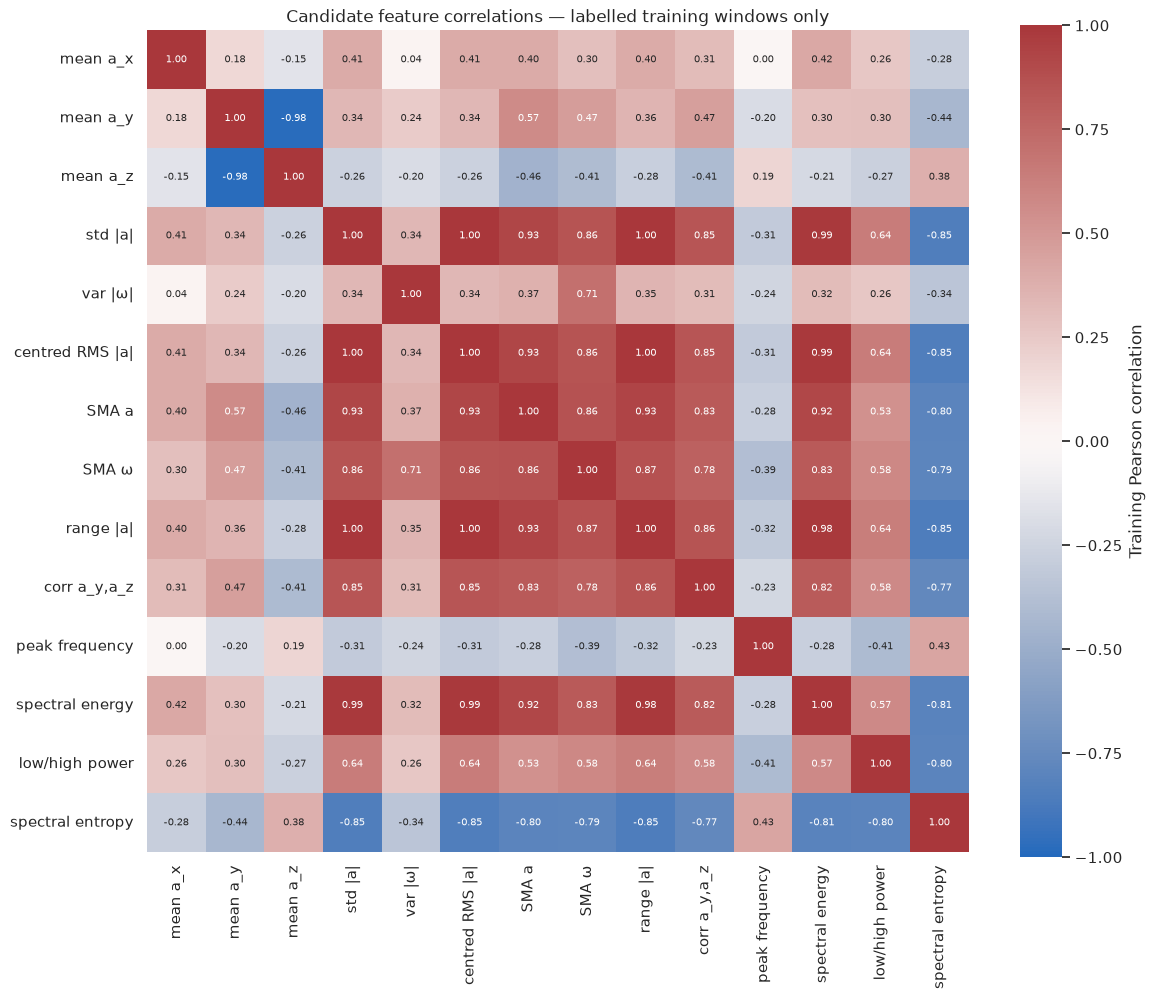

PASS: no retained feature pair exceeds the training correlation threshold


In [20]:
display(feature_result["selection"])
short_names = {
    "mean_acc_x": "mean a_x", "mean_acc_y": "mean a_y", "mean_acc_z": "mean a_z",
    "std_acc_mag": "std |a|", "var_gyro_mag": "var |ω|", "rms_centered_acc_mag": "centred RMS |a|",
    "sma_acc": "SMA a", "sma_gyro": "SMA ω", "ptp_acc_mag": "range |a|", "corr_acc_yz": "corr a_y,a_z",
    "dominant_freq_acc": "peak frequency", "spectral_energy_acc": "spectral energy",
    "band_energy_ratio_acc": "low/high power", "spectral_entropy_acc": "spectral entropy",
}
fig, ax = plt.subplots(figsize=(12, 10))
correlation_plot = feature_result["correlations"].rename(index=short_names, columns=short_names)
sns.heatmap(correlation_plot, vmin=-1, vmax=1, center=0, cmap="vlag", annot=True, fmt=".2f",
            annot_kws={"size": 7}, square=True, ax=ax, cbar_kws={"label": "Training Pearson correlation"})
ax.set_title("Candidate feature correlations — labelled training windows only")
fig.tight_layout()
fig.savefig(FIG_DIR / "features_training_correlation.png", dpi=150, bbox_inches="tight")
plt.show()
retained_correlation = training_candidates[selected_features].corr().to_numpy()
upper = retained_correlation[np.triu_indices(len(selected_features), 1)]
assert np.max(np.abs(upper)) <= .95 + 1e-12
print("PASS: no retained feature pair exceeds the training correlation threshold")

The fitted selection retains **10 features (7 time-domain and 3 FFT-derived)**.
Mean acceleration on z is redundant with y (`r ≈ -0.983`); centred RMS duplicates
standard deviation (`r = 1`); acceleration range and spectral energy also exceed
the threshold against standard deviation. The three retained FFT features are
dominant frequency, band-energy ratio and spectral entropy. Full candidate
values remain available for the training audit; removed columns are absent from
the normalised observation vectors.

### 4.3 Z-score normalisation fitted on labelled training only

For each retained feature, `z = (x − training_mean) / training_std`, using
population standard deviation. The fitted vectors, feature order, source hashes
and training recording IDs are saved in `data/features/transform.json`.
Constant training features are removed before fitting. Test and optional
unlabelled windows are transformed without refitting or clipping.

Features have mixed units and numerical scales. Z-scoring provides numerical
conditioning and a consistent meaning for the HMM's later variance floor.
A Gaussian with freely rescaled means/variances is not inherently dominated by
large units; the practical reasons here are conditioning and regularisation.
Min–max scaling is more sensitive to the chosen extreme observations. Test means
and standard deviations are **not** expected to be zero and one.

In [21]:
scaled_training = pd.concat(feature_result["normalized"]["train"].values(), ignore_index=True)
normalisation_audit = pd.DataFrame({
    "feature": selected_features,
    "training_mean": feature_config["statistics"]["mean"],
    "training_std": feature_config["statistics"]["std"],
    "z_mean": scaled_training[selected_features].mean().to_numpy(),
    "z_std": scaled_training[selected_features].std(ddof=0).to_numpy(),
})
display(normalisation_audit)
np.testing.assert_allclose(scaled_training[selected_features].mean(), 0, atol=1e-10)
np.testing.assert_allclose(scaled_training[selected_features].std(ddof=0), 1, atol=1e-10)
assert set(feature_config["fit_sequences"]) == {name for name, _ in training_sequences}
assert not (set(feature_config["fit_sequences"]) & {name for name, _ in test_sequences})
for split, frames in feature_result["normalized"].items():
    for name, frame in frames.items():
        assert np.isfinite(frame[selected_features]).all().all()
        raw_features = feature_result["raw"][split][name][selected_features]
        np.testing.assert_allclose(frame[selected_features], zscore_transform(raw_features, feature_config["statistics"]), atol=1e-12)
        if split == "unlabelled":
            assert "activity" not in frame
print("PASS: all features finite; fit IDs are train-only; one frozen transform used for all splits")

,feature,training_mean,training_std,z_mean,z_std
0,mean_acc_x,0.107,0.222,2.102e-17,1.0
1,mean_acc_y,6.927,4.139,1.261e-16,1.0
2,std_acc_mag,2.307,4.027,-4.204e-17,1.0
3,var_gyro_mag,0.049,0.130,1.051e-17,1.0
4,sma_acc,12.759,2.579,8.409e-16,1.0
5,sma_gyro,0.384,0.501,2.102e-17,1.0
6,corr_acc_yz,0.274,0.401,-4.204e-17,1.0
7,dominant_freq_acc,2.885,1.797,0.000e+00,1.0
8,band_energy_ratio_acc,2.406,3.217,-2.102e-17,1.0
9,spectral_entropy_acc,0.692,0.147,-2.943e-16,1.0


PASS: all features finite; fit IDs are train-only; one frozen transform used for all splits


### 4.4 Feature distributions and training interpretation

These box plots show only the retained, standardised **training** features. The
raw-unit summary beneath them makes the intensity and orientation checks easier
to interpret. Overlapping windows are correlated observations; window counts
must not be described as counts of independent participants or recordings.

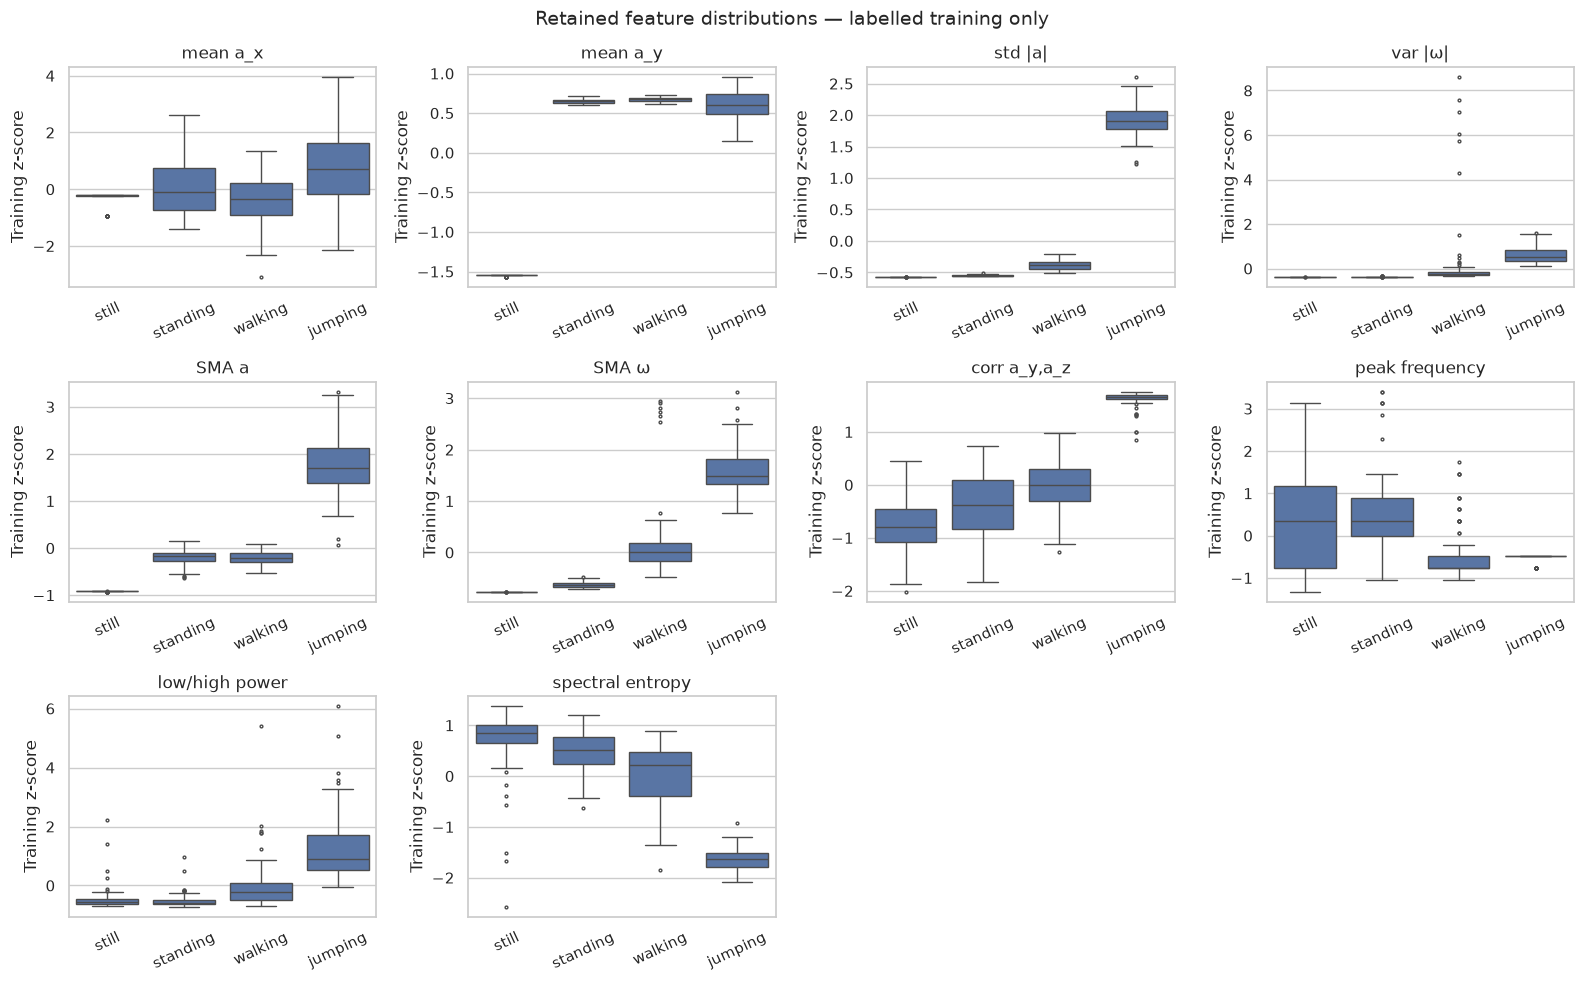

,mean_acc_y,std_acc_mag,dominant_freq_acc,spectral_entropy_acc
activity,,,,
still,0.530,0.003,3.5,0.817
standing,9.607,0.090,3.5,0.768
walking,9.735,0.744,1.5,0.723
jumping,9.445,9.979,2.0,0.450


,min,median,max
activity,,,
still,0.435,0.530,0.535
standing,9.428,9.607,9.874
walking,9.492,9.735,9.933
jumping,7.546,9.445,10.894


In [22]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, name in zip(axes.flat, selected_features):
    sns.boxplot(data=scaled_training, x="activity", y=name, order=ACTIVITIES,
                color="C0", fliersize=2, ax=ax)
    ax.set_title(short_names[name])
    ax.set(xlabel="", ylabel="Training z-score")
    ax.tick_params(axis="x", rotation=25)
for ax in list(axes.flat)[len(selected_features):]:
    ax.set_visible(False)
fig.suptitle("Retained feature distributions — labelled training only", fontsize=14)
fig.tight_layout()
fig.savefig(FIG_DIR / "features_training_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()
training_summary = training_candidates.groupby("activity")[["mean_acc_y", "std_acc_mag", "dominant_freq_acc", "spectral_entropy_acc"]].median().reindex(ACTIVITIES)
display(training_summary)
display(training_candidates.groupby("activity").mean_acc_y.agg(["min", "median", "max"]).reindex(ACTIVITIES))

The raw training medians of acceleration-magnitude standard deviation increase
from **still ≈0.0035**, **standing ≈0.0903**, **walking ≈0.7444**, to **jumping
≈9.9793 m/s²**. Mean acceleration on y distinguishes the protocol's flat-phone
still setup (median ≈0.53 m/s²) from the upright standing setup (≈9.61 m/s²).
This is an orientation cue, not evidence of invariance to how a person holds the
phone. The unlabelled session grip difference remains a limitation.

The dominant-frequency medians are about 1.5 Hz for walking and 2 Hz for jumping;
the 3.5 Hz medians in still/standing describe low-energy fluctuations rather than
steps. Jumping's lower spectral entropy is consistent with concentrated repeated
motion. These are training observations only; they do not establish test accuracy.

### 4.5 Model-ready sequences and Phase 5 checkpoint

Use `load_feature_sequences(ROOT, split)` to obtain separate dictionaries with
`name`, `X`, `y` and `windows`. `X` contains only the ten ordered feature columns;
timestamps, window IDs and activity labels never enter it as numeric features.
`y` follows the fixed state order still=0, standing=1, walking=2, jumping=3;
unlabelled blocks have `y=None`. The loader checks provenance and output hashes.

The four unlabelled blocks are available for optional later Baum–Welch training,
but neither they nor the test data contributed to selection or scaling. There
are no ground-truth labels for computing accuracy on those blocks. During any
future training-only cross-validation, refit selection and scaling within each
training fold rather than reusing the full-training transform for validation.

In [23]:
feature_train_sequences = load_feature_sequences(ROOT, "train")
feature_test_sequences = load_feature_sequences(ROOT, "test")
feature_unlabelled_sequences = load_feature_sequences(ROOT, "unlabelled")
for split, items in [("train", feature_train_sequences), ("test", feature_test_sequences), ("unlabelled", feature_unlabelled_sequences)]:
    assert all(item["X"].shape[1] == len(selected_features) for item in items)
    print(f"{split}: {len(items)} independent sequences; {sum(len(item['X']) for item in items)} windows; D={len(selected_features)}")
print("PASS — Phase 5 feature/window/normalisation checks complete")
print("No HMM training or test performance evaluation has been performed.")

train: 44 independent sequences; 338 windows; D=10
test: 8 independent sequences; 65 windows; D=10
unlabelled: 4 independent sequences; 137 windows; D=10
PASS — Phase 5 feature/window/normalisation checks complete
No HMM training or test performance evaluation has been performed.


## 5. HMM implementation

The next cell defines the complete from-scratch NumPy implementation: `logsumexp`,
`log_probabilities` and the `GaussianHMM` class (diagonal Gaussian emissions, scaled
forward–backward, Viterbi, supervised initialisation and Baum–Welch). The same code is
saved as `scripts/hmm.py` so the training and evaluation scripts can import it. The cell
after it checks that both copies behave identically, and a regression test checks that
the cell text equals the file. No external HMM library is used.

The later activity model has four states (still, standing, walking, jumping) and
10 standardised features. Its parameters are initial probabilities pi (N,),
row-stochastic transitions A (N,N), means (N,D), and diagonal variances (N,D).
The variance floor is 1e-3. With 71–99 overlapping training windows per activity,
a full covariance would require 55 entries per state; diagonal covariance reduces
the estimation burden. Neither form makes the overlapping windows independent.

**This phase fits only toy/synthetic arrays.** Existing feature sequences above
are not passed to any HMM fitting or scoring method.

In [24]:
"""From-scratch NumPy diagonal Gaussian HMM; sequences remain independent.

Forward/backward messages are scaled in log space: log_scales[t] is the log
predictive density at t, and its sum is the sequence log likelihood. No HMM
library or real activity data is used by this module's verification examples.
"""

import numpy as np


def logsumexp(values, axis=None):
    """Stable log(sum(exp(values))) along axis; all -inf slices stay -inf."""
    values = np.asarray(values, dtype=float)
    maximum = np.max(values, axis=axis, keepdims=True)
    safe = np.where(np.isfinite(maximum), maximum, 0.0)
    with np.errstate(divide="ignore"):
        result = safe + np.log(np.sum(np.exp(values - safe), axis=axis, keepdims=True))
    return result.squeeze() if axis is None else np.squeeze(result, axis=axis)


def log_probabilities(probabilities):
    """Map probability array to logs, preserving exact zeros as -inf."""
    with np.errstate(divide="ignore"):
        return np.log(probabilities)


class GaussianHMM:
    """N states, D features, parameters pi(N), A(N,N), means/variances(N,D)."""

    def __init__(self, n_states, n_features, var_floor=1e-3, tol=1e-4, max_iter=500):
        """Configure positive N,D, variance floor, absolute LL tolerance and cap."""
        for name, value in [("n_states", n_states), ("n_features", n_features), ("max_iter", max_iter)]:
            if isinstance(value, bool) or not isinstance(value, (int, np.integer)) or value < 1:
                raise ValueError(f"{name} must be a positive integer")
        if not np.isfinite(var_floor) or var_floor <= 0 or not np.isfinite(tol) or tol <= 0:
            raise ValueError("var_floor and tol must be finite and positive")
        self.n_states, self.n_features = n_states, n_features
        self.var_floor, self.tol, self.max_iter = float(var_floor), float(tol), max_iter
        self.pi = self.A = self.means = self.variances = None

    def set_parameters(self, pi, A, means, variances):
        """Copy and validate pi(N), A(N,N), means(N,D), variances(N,D); return self."""
        previous = self.pi, self.A, self.means, self.variances
        self.pi, self.A, self.means, self.variances = [
            np.array(p, dtype=float, copy=True) for p in (pi, A, means, variances)]
        try:
            self._validate_parameters()
        except ValueError:
            self.pi, self.A, self.means, self.variances = previous
            raise
        return self

    def _validate_parameters(self):
        """Check finite parameter shapes, probability sums and variance bounds."""
        for value, shape in [(self.pi, (self.n_states,)), (self.A, (self.n_states, self.n_states)),
                             (self.means, (self.n_states, self.n_features)),
                             (self.variances, (self.n_states, self.n_features))]:
            if value is None or value.shape != shape or not np.isfinite(value).all():
                raise ValueError("Initialise finite parameters with the required shapes")
        if (self.pi < 0).any() or (self.A < 0).any():
            raise ValueError("Probabilities must be nonnegative")
        if not np.isclose(self.pi.sum(), 1, atol=1e-12, rtol=0) or not np.allclose(self.A.sum(axis=1), 1, atol=1e-12, rtol=0):
            raise ValueError("pi and each row of A must sum to one")
        if (self.variances < self.var_floor).any():
            raise ValueError("Variances must meet var_floor")

    def _validate_X(self, X):
        """Return finite nonempty float observations of shape (T,D)."""
        X = np.asarray(X, dtype=float)
        if X.ndim != 2 or X.shape[1] != self.n_features or len(X) == 0 or not np.isfinite(X).all():
            raise ValueError("X must be a nonempty finite (T,D) array")
        return X

    def _sequences(self, X_list):
        """Validate a nonempty list of separate (T_s,D) arrays; never concatenate."""
        if isinstance(X_list, np.ndarray):
            raise ValueError("Pass a list of sequences, including for a single recording")
        sequences = [self._validate_X(X) for X in X_list]
        if not sequences:
            raise ValueError("At least one sequence is required")
        return sequences

    def _log_emission(self, X):
        """Diagonal Gaussian log densities (T,N) for X(T,D), including constants."""
        self._validate_parameters()
        X = self._validate_X(X)
        with np.errstate(over="ignore"):
            result = -0.5 * (self.n_features * np.log(2 * np.pi)
                             + np.log(self.variances).sum(axis=1)
                             + np.sum((X[:, None, :] - self.means) ** 2 / self.variances, axis=2))
        if not np.isfinite(result).all():
            raise ValueError("Gaussian log density exceeds floating-point range")
        return result

    def _validate_log_B(self, log_B):
        """Validate emission log weights (T,N); permit impossible states (-inf)."""
        log_B = np.asarray(log_B, dtype=float)
        if (log_B.ndim != 2 or log_B.shape[1] != self.n_states or len(log_B) == 0
                or np.isnan(log_B).any() or np.isposinf(log_B).any()):
            raise ValueError("log_B must be (T,N) without NaN or +inf")
        return log_B

    def _forward(self, log_B):
        """Return normalised log_alpha(T,N), log_scales(T), scalar log likelihood."""
        self._validate_parameters()
        log_B = self._validate_log_B(log_B)
        log_A = log_probabilities(self.A)
        alpha = np.empty_like(log_B)
        scales = np.empty(len(log_B))
        for t in range(len(log_B)):
            predicted = log_probabilities(self.pi) if t == 0 else logsumexp(alpha[t-1, :, None] + log_A, axis=0)
            row = predicted + log_B[t]
            scales[t] = logsumexp(row)
            if not np.isfinite(scales[t]):
                raise ValueError("Observation sequence has no finite-probability path")
            alpha[t] = row - scales[t]
        return alpha, scales, float(scales.sum())

    def _backward(self, log_B, log_scales):
        """Return scaled log_beta(T,N), using forward log_scales(T); terminal zero."""
        self._validate_parameters()
        log_B = self._validate_log_B(log_B)
        log_scales = np.asarray(log_scales, dtype=float)
        if log_scales.shape != (len(log_B),) or not np.isfinite(log_scales).all():
            raise ValueError("Expected finite forward log_scales(T)")
        beta = np.zeros_like(log_B)
        log_A = log_probabilities(self.A)
        for t in range(len(log_B) - 2, -1, -1):
            beta[t] = logsumexp(log_A + log_B[t+1] + beta[t+1], axis=1) - log_scales[t+1]
        return beta

    def _posteriors(self, X):
        """Return gamma(T,N), xi(T-1,N,N), LL; no transitions across sequences."""
        log_B = self._log_emission(X)
        alpha, scales, likelihood = self._forward(log_B)
        beta = self._backward(log_B, scales)
        weights = alpha + beta
        gamma = np.exp(weights - logsumexp(weights, axis=1)[:, None])
        xi = np.empty((len(log_B)-1, self.n_states, self.n_states))
        for t in range(len(xi)):
            weights = alpha[t, :, None] + log_probabilities(self.A) + log_B[t+1] + beta[t+1]
            xi[t] = np.exp(weights - logsumexp(weights))
        return gamma, xi, likelihood

    def score(self, X_list):
        """Sum independent sequence log densities for a list of (T_s,D) arrays."""
        return float(sum(self._forward(self._log_emission(X))[2] for X in self._sequences(X_list)))

    def predict_proba(self, X):
        """Return smoothed state posterior gamma(T,N) for one X(T,D) sequence."""
        return self._posteriors(X)[0]

    def predict_viterbi(self, X):
        """Return the most likely joint state path (T,) for X(T,D), in log space.

        Backpointers select the whole path, not per-window posterior maxima.
        Exact ties choose the lowest predecessor/final state index.
        """
        log_B = self._log_emission(X)
        log_A = log_probabilities(self.A)
        delta = log_probabilities(self.pi) + log_B[0]
        back = np.zeros(log_B.shape, dtype=np.int64)
        for t in range(1, len(log_B)):
            candidates = delta[:, None] + log_A
            back[t] = np.argmax(candidates, axis=0)
            delta = candidates[back[t], np.arange(self.n_states)] + log_B[t]
        path = np.empty(len(log_B), dtype=np.int64)
        path[-1] = np.argmax(delta)
        for t in range(len(log_B)-1, 0, -1):
            path[t-1] = back[t, path[t]]
        return path

    def _m_step(self, sequences, posteriors):
        """Update parameters from X_s(T_s,D), gamma_s(T_s,N), xi_s(T_s-1,N,N).

        This is maximum-likelihood EM with a constrained variance floor, without
        probability pseudocounts. Unoccupied states/transition rows retain their
        previous parameters. Each sequence contributes its own initial state.
        When update_transitions_ is False, A is held fixed (a partial M-step that
        still cannot decrease the likelihood).
        """
        weights = sum(gamma.sum(axis=0) for gamma, _, _ in posteriors)
        initial = sum(gamma[0] for gamma, _, _ in posteriors)
        transitions = sum(xi.sum(axis=0) for _, xi, _ in posteriors)
        means = self.means.copy()
        variances = self.variances.copy()
        occupied = weights > 0
        first_moment = sum(gamma.T @ X for X, (gamma, _, _) in zip(sequences, posteriors))
        means[occupied] = first_moment[occupied] / weights[occupied, None]
        # Centre at the NEW means, avoiding E[X²] - E[X]² cancellation.
        squared = sum(np.einsum('tn,tnd->nd', gamma, (X[:, None, :] - means)**2)
                      for X, (gamma, _, _) in zip(sequences, posteriors))
        variances[occupied] = np.maximum(squared[occupied] / weights[occupied, None], self.var_floor)
        A = self.A.copy()
        if getattr(self, "update_transitions_", True):
            row_counts = transitions.sum(axis=1)
            active = row_counts > 0
            A[active] = transitions[active] / row_counts[active, None]
        self.set_parameters(initial / initial.sum(), A, means, variances)

    def fit_supervised(self, X_list, y_list, transition_prior=1.0, initial_prior=1.0):
        """Initialise from X_s(T_s,D), integer labels y_s(T_s,) in [0,N); return self.

        Means/population variances use labelled samples, with var_floor. Count
        starts once per sequence and transitions only within each sequence.
        Default Laplace pseudocounts are one per entry; explicit positive (N,N)
        transition and (N,) initial pseudocount arrays are also supported. These
        priors initialise parameters only, and do not enter subsequent EM.
        Missing labelled states fail rather than inventing their emissions.
        """
        sequences = self._sequences(X_list)
        labels = [np.asarray(y) for y in y_list]
        if len(labels) != len(sequences):
            raise ValueError("Provide one label array per sequence")
        for X, y in zip(sequences, labels):
            if (y.shape != (len(X),) or not np.issubdtype(y.dtype, np.integer)
                    or (y < 0).any() or (y >= self.n_states).any()):
                raise ValueError("Labels must be integer states with shape (T_s,)")
        transition_prior = np.broadcast_to(np.asarray(transition_prior, dtype=float), (self.n_states, self.n_states)).copy()
        initial_prior = np.broadcast_to(np.asarray(initial_prior, dtype=float), (self.n_states,)).copy()
        if any(not np.isfinite(p).all() or (p <= 0).any() for p in (transition_prior, initial_prior)):
            raise ValueError("Prior pseudocounts must be finite and strictly positive")
        starts = np.zeros(self.n_states)
        transitions = np.zeros((self.n_states, self.n_states))
        for y in labels:
            starts[y[0]] += 1
            np.add.at(transitions, (y[:-1], y[1:]), 1)
        means, variances, counts = [], [], []
        for state in range(self.n_states):
            values = np.concatenate([X[y == state] for X, y in zip(sequences, labels)])
            if len(values) == 0:
                raise ValueError(f"No labelled observations for state {state}")
            means.append(values.mean(axis=0))
            variances.append(np.maximum(values.var(axis=0), self.var_floor))
            counts.append(len(values))
        initial = starts + initial_prior
        A = transitions + transition_prior
        self.set_parameters(initial / initial.sum(), A / A.sum(axis=1, keepdims=True), means, variances)
        self.supervised_counts_ = {"starts": starts, "transitions": transitions,
                                   "observations": np.array(counts),
                                   "initial_prior": initial_prior, "transition_prior": transition_prior}
        return self

    def _invariants(self):
        """Validate parameters and return scalar diagnostics for one M-step."""
        self._validate_parameters()
        return {"pi_sum_error": float(abs(self.pi.sum()-1)),
                "A_row_sum_error": float(np.max(abs(self.A.sum(axis=1)-1))),
                "minimum_variance": float(self.variances.min())}

    def fit_baum_welch(self, X_list, update_transitions=True):
        """Fit independent X_s(T_s,D) arrays from existing parameters; return self.

        history_ contains the initial total LL and each accepted update's LL.
        Stop when absolute total LL improvement < tol; max_iter is only a cap.
        A meaningful decrease raises and restores the previous parameters. A
        tiny roundoff decrease is rolled back and reported as a numerical plateau.
        No labels, test data, smoothing counts or cross-file transitions enter EM.
        update_transitions=False keeps A fixed and re-estimates pi and emissions
        only; use it when the sequences carry no information about state changes.
        """
        sequences = self._sequences(X_list)
        self._validate_parameters()
        self.update_transitions_ = bool(update_transitions)
        self.history_ = [self.score(sequences)]
        self.invariant_history_ = []
        self.converged_, self.n_iter_, self.stop_reason_ = False, 0, "max_iter"
        for iteration in range(1, self.max_iter + 1):
            posteriors = [self._posteriors(X) for X in sequences]
            previous = tuple(p.copy() for p in (self.pi, self.A, self.means, self.variances))
            try:
                self._m_step(sequences, posteriors)
                invariant = self._invariants()
                likelihood = self.score(sequences)
                delta = likelihood - self.history_[-1]
                roundoff = 1e-9 + 100*np.finfo(float).eps*abs(self.history_[-1])
                if delta < -roundoff:
                    raise FloatingPointError(f"EM log likelihood decreased by {delta}")
            except Exception:
                self.set_parameters(*previous)
                raise
            if delta < 0:
                self.set_parameters(*previous)
                likelihood, delta = self.history_[-1], 0.0
                invariant = self._invariants()
                self.stop_reason_ = "roundoff_plateau"
            self.history_.append(likelihood)
            self.invariant_history_.append(invariant)
            self.n_iter_ = iteration
            if abs(delta) < self.tol:
                self.converged_ = True
                if self.stop_reason_ != "roundoff_plateau":
                    self.stop_reason_ = "likelihood_tolerance"
                break
        return self

In [25]:
import inspect
from IPython.display import Code
from scripts import hmm as hmm_module
from scripts.verify_hmm import run_verification

# The notebook class and the module class must give identical results.
rng = np.random.default_rng(0)
toy = dict(pi=[.4, .6], A=[[.9, .1], [.2, .8]], means=[[0., 1.], [2., -1.]], variances=[[1., .5], [.7, 1.2]])
toy_X = [rng.normal(size=(30, 2)) for _ in range(3)]
notebook_hmm = GaussianHMM(2, 2).set_parameters(**toy)
module_hmm = hmm_module.GaussianHMM(2, 2).set_parameters(**toy)
assert notebook_hmm.score(toy_X) == module_hmm.score(toy_X)
assert all((notebook_hmm.predict_viterbi(X) == module_hmm.predict_viterbi(X)).all() for X in toy_X)
for update in (True, False):
    a = GaussianHMM(2, 2).set_parameters(**toy).fit_baum_welch(toy_X, update_transitions=update)
    b = hmm_module.GaussianHMM(2, 2).set_parameters(**toy).fit_baum_welch(toy_X, update_transitions=update)
    assert a.history_ == b.history_ and np.array_equal(a.A, b.A) and np.array_equal(a.means, b.means)
print("PASS — notebook GaussianHMM matches scripts/hmm.py")

PASS — notebook GaussianHMM matches scripts/hmm.py


### 5.1 Scaling, sequence boundaries and convergence

The diagonal Gaussian log density includes D log(2 pi), the log variances, and
the variance-weighted squared deviations. `_forward` stores **normalised log
alpha** and **log scaling constants**, whose sum gives the sequence log density.
`_backward` subtracts the next forward scale at each step; its final row is zero.
Gamma and xi are normalised from these log messages. Exact zero probabilities
remain minus infinity. Viterbi uses log-space maximisation and backpointers to
return the best joint path, rather than independent posterior maxima.

`fit_supervised` computes labelled means/population variances and adds explicit
Laplace counts (one per entry by default) to initial/transition counts. A start
is counted per recording; a transition is counted only inside a recording.
An explicit prior supports transitions absent from single-activity training clips.
Unverified session annotations never supply supervised transition evidence.

Baum–Welch sums independently evaluated sequence posteriors. Its M-step uses
expected counts and weighted emission moments, with a variance floor. Zero-count
rows/states retain their previous parameters. Initialisation pseudocounts are
not reapplied during maximum-likelihood EM. `fit_baum_welch(X, update_transitions=False)`
holds A fixed and re-estimates pi and the emissions only; this partial M-step
still cannot decrease the likelihood. Every M-step checks parameter shapes,
finiteness, probability sums and variance bounds. A meaningful LL decrease raises
and restores the previous parameters; a tiny numerical decrease is rolled back
and reported as a roundoff plateau.

The default stopping criterion is **absolute total LL improvement < 1e-4**;
500 iterations is only a safety cap. `history_`, `converged_`, `stop_reason_`,
`n_iter_` and per-step invariant diagnostics make termination auditable.

## 6. Model verification — exact and synthetic ground truth

The assertions in `scripts/verify_hmm.py` run here and in regression tests.
The small example enumerates **all 64 paths** for N=2, T=6 using an independent
Gaussian PDF. It verifies likelihood, the best joint path, every gamma and xi,
normalisation and adjacent marginals, plus one exact EM update. A separate
ordinary backward recurrence verifies likelihood without the implementation's
scaled messages.

The larger example samples twelve independent 250-step sequences from a known
three-state, two-feature HMM (data seed 2026). A single random initialisation
(seed 7) uses Dirichlet probabilities, uniformly sampled means within observed
bounds and pooled variances. No hidden state labels enter EM. After fitting,
all 3! permutations are considered to align means with known synthetic truth;
A is permuted along both axes. Recovery thresholds are max A error <0.06 and
max mean error <0.15. They measure finite-sample recovery, not exact equality.

In [26]:
verification = run_verification(ROOT / "data/verification/hmm.json")
exact_check = verification["exact"]
recovery = verification["synthetic"]
assert exact_check["paths_enumerated"] == 64
assert exact_check["likelihood_absolute_error"] < 1e-15
assert exact_check["viterbi_path"] == [0, 0, 1, 1, 1, 0]
assert exact_check["maximum_gamma_error"] < 1e-12
assert exact_check["maximum_xi_error"] < 1e-12
assert exact_check["exact_em_step_passed"]
display(pd.DataFrame([exact_check]).T.rename(columns={0: "exact verification"}))

,exact verification
paths_enumerated,64
brute_force_likelihood,0.0
forward_log_likelihood,-9.006
backward_likelihood,0.0
likelihood_absolute_error,0.0
viterbi_path,"[0, 0, 1, 1, 1, 0]"
maximum_gamma_error,0.0
maximum_xi_error,0.0
exact_em_step_passed,True


In [27]:
ll_history = np.asarray(recovery["history"])
assert (np.diff(ll_history) >= 0).all()
assert recovery["converged"] and recovery["stop_reason"] == "likelihood_tolerance"
assert recovery["iterations"] < recovery["iteration_cap"]
assert abs(np.diff(ll_history)[-1]) < recovery["tol"]
assert recovery["maximum_A_error"] < recovery["A_error_tolerance"]
assert recovery["maximum_mean_error"] < recovery["mean_error_tolerance"]
invariant_checks = pd.DataFrame(recovery["invariant_history"])
assert len(invariant_checks) == recovery["iterations"]
assert (invariant_checks.pi_sum_error <= 1e-12).all()
assert (invariant_checks.A_row_sum_error <= 1e-12).all()
assert (invariant_checks.minimum_variance >= 1e-3).all()
display(pd.Series({k: recovery[k] for k in ["iterations", "iteration_cap", "stop_reason",
    "final_improvement", "tol", "maximum_A_error", "maximum_mean_error"]}, name="synthetic recovery"))
display(invariant_checks)

iterations                               7
iteration_cap                          500
stop_reason           likelihood_tolerance
final_improvement                      0.0
tol                                    0.0
maximum_A_error                      0.014
maximum_mean_error                   0.032
Name: synthetic recovery, dtype: object

,pi_sum_error,A_row_sum_error,minimum_variance
0,2.220e-16,0.000e+00,2.891
1,0.000e+00,0.000e+00,0.617
2,0.000e+00,0.000e+00,0.344
3,0.000e+00,0.000e+00,0.342
4,0.000e+00,1.110e-16,0.343
5,1.110e-16,2.220e-16,0.313
6,0.000e+00,0.000e+00,0.313


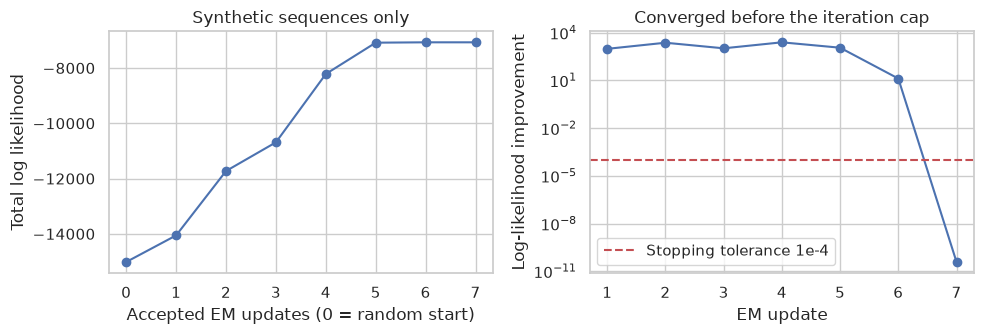

,0,1,2
True state,,,
0,0.91,0.06,0.03
1,0.04,0.90,0.06
2,0.05,0.05,0.90


,0,1,2
Matched fitted state,,,
0,0.910,0.066,0.024
1,0.034,0.893,0.073
2,0.042,0.044,0.914


,true mean 1,true mean 2,fitted mean 1,fitted mean 2
0,-4.0,-2.0,-3.968,-2.011
1,0.0,3.0,-0.008,3.007
2,4.0,-1.0,3.977,-0.987


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(np.arange(len(ll_history)), ll_history, marker="o")
axes[0].set(xlabel="Accepted EM updates (0 = random start)", ylabel="Total log likelihood",
            title="Synthetic sequences only")
axes[1].semilogy(np.arange(1, len(ll_history)), np.diff(ll_history), marker="o")
axes[1].axhline(recovery["tol"], color="C3", linestyle="--", label="Stopping tolerance 1e-4")
axes[1].set(xlabel="EM update", ylabel="Log-likelihood improvement", title="Converged before the iteration cap")
axes[1].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "hmm_synthetic_convergence.png", dpi=180, bbox_inches="tight")
plt.show()

display(pd.DataFrame(recovery["truth"]["A"]).rename_axis("True state"))
display(pd.DataFrame(recovery["matched_A"]).rename_axis("Matched fitted state"))
mean_comparison = pd.DataFrame(np.column_stack([recovery["truth"]["means"], recovery["matched_means"]]),
    columns=["true mean 1", "true mean 2", "fitted mean 1", "fitted mean 2"])
display(mean_comparison)

### 6.1 Phase 6 checkpoint and interpretation

All six planned checks pass: exact likelihood, exact Viterbi, forward/backward
consistency, monotonic EM, synthetic parameter recovery, and invariants after
every M-step. The single synthetic run converges in **7 iterations**, with a
final improvement of approximately **3.82e-11**, below 1e-4. The maximum A error
is **0.01421** and maximum mean error is **0.03212** after state matching.

These are algorithm-verification results, not activity classification metrics.
The synthetic states are deliberately well separated; one successful start
does not prove global EM convergence or success for all initialisations.
Initial-distribution recovery is not claimed from only twelve sequence starts.
The full regression suite also covers singleton sequences, impossible paths,
zero occupancy, variance floors, long low-density sequences, supervised
sequence boundaries, rollback on a broken M-step and iteration-cap reporting.

`data/verification/hmm.json` records the actual history, invariants, parameters,
seeds, NumPy version and source hashes. Phase 7 will train and evaluate the
activity model using the fixed feature order, training-only choices and eight
independent held-out test clips. No activity HMM has been fitted or evaluated.

In [29]:
assert verification["passed"]
print("PASS — all six Phase 6 HMM verification checks")
print("Scope: exact toy example and generated synthetic sequences only")
print("Next: Phase 7 activity-model training and held-out evaluation")

PASS — all six Phase 6 HMM verification checks
Scope: exact toy example and generated synthetic sequences only
Next: Phase 7 activity-model training and held-out evaluation


## 7. Training — fixed protocol and independent recordings

The **44 labelled training clips (338 windows)** are the only fitting inputs. The ten
feature columns and z-score parameters remain fixed from Phase 5. The four unlabelled
session blocks are not used for fitting (uncertain boundaries and a different grip);
Section 8.4 decodes them only to inspect predicted transitions.

Four models are trained with the planned settings (variance floor 1e-3, absolute LL
tolerance 1e-4, max_iter 500, Laplace pseudocount one per entry):

| Model | Role |
|---|---|
| Supervised HMM | Parameters from labelled counts and class statistics |
| **Baum–Welch, A fixed** | **Primary**: EM re-estimates pi and the Gaussian emissions |
| Baum–Welch, free A | Comparison: EM also re-estimates A |
| Independent Gaussian | Baseline: supervised emissions per window, no A |

**Why A is fixed during EM.** Every training clip contains one activity, so the data
hold no evidence about switching. In free EM the expected count of every unobserved
transition is zero, which drives P(still→still) and P(jumping→jumping) to exactly 1: a
model that can never leave those states. An earlier version of this notebook used that
free-A model as primary. After inspecting its fitted A, the primary model now keeps the
supervised Laplace prior for A. The decision came from the fitted parameters, not from
test scores, and both EM variants make identical held-out predictions (Section 8).

Every recording is its own sequence; no cross-file transitions are counted. Both HMM
state maps are fitted with Hungarian matching on **training** Viterbi predictions only.
The baseline uses the supervised emission log density plus the initial log probability
at each window, ignoring A and neighbouring windows.

In [30]:
from scripts.train_activity import train_models, load_models
from scripts.evaluate_activity import evaluate_models, confusion_matrix, metrics_from_confusion
from scripts.activity_plots import (generate_figures, aligned_parameters,
    plot_transition_comparison, plot_gaussians, plot_timelines, decode_sessions)

activity_fit = train_models(ROOT)
activity_models = load_models(ROOT)
assert activity_models["fit_windows"] == 338
assert len(activity_models["fit_sequences"]) == 44
assert not activity_models["protocol"]["include_unlabelled"]
assert activity_models["protocol"]["primary_model"] == "baum_welch"
assert not activity_models["protocol"]["em_update_transitions"]
assert activity_models["models"]["baum_welch"]["parameters"]["A"] == activity_models["models"]["supervised"]["parameters"]["A"]
display(pd.Series(activity_models["protocol"], name="Fixed protocol"))
activity_em = activity_models["models"]["baum_welch"]
assert activity_em["converged"]
assert activity_em["stop_reason"] == "likelihood_tolerance"
assert (np.diff(activity_em["history"]) >= 0).all()
assert abs(np.diff(activity_em["history"])[-1]) < 1e-4
assert activity_em["iterations"] < 500
for name in ["baum_welch", "baum_welch_free_transitions"]:
    em = activity_models["models"][name]
    print(f"{name}: {em['iterations']} updates; LL {em['history'][0]:.6f} → {em['history'][-1]:.6f}; "
          f"final improvement {np.diff(em['history'])[-1]:.3g}")

primary_model                                                    baum_welch
models                    [supervised, baum_welch, baum_welch_free_trans...
n_states                                                                  4
var_floor                                                             0.001
tol                                                                     0.0
max_iter                                                                500
transition_pseudocount                                                  1.0
initial_pseudocount                                                     1.0
em_update_transitions                                                 False
transition_policy         Every labelled training clip contains one acti...
training_split                                                        train
include_unlabelled                                                    False
unlabelled_policy         Excluded a priori: unverified boundaries and c...
mapping_poli

baum_welch: 7 updates; LL 654.817634 → 664.095147; final improvement 1.18e-06
baum_welch_free_transitions: 8 updates; LL 654.817634 → 674.289539; final improvement 3.59e-05


### 7.1 Mapping and parameter checks

Supervised counts contain only same-activity transitions; cross-activity transition
probabilities come from explicit pseudocounts. Both training-only Hungarian maps
are identity in this run. Mapping correctness does not imply perfect accuracy.
Positive Gaussian log likelihoods are valid continuous log densities and must
not be confused with classification probabilities or percentages.

In [31]:
mapping_rows = []
for model_name, record in activity_models["models"].items():
    for state, label in enumerate(record["state_to_label"]):
        mapping_rows.append({"model": model_name, "state": state, "activity": ACTIVITIES[label]})
    values = aligned_parameters(activity_models, model_name)
    assert np.allclose(values["A"].sum(axis=1), 1, atol=1e-12)
    assert np.isclose(values["pi"].sum(), 1, atol=1e-12)
    assert (values["variances"] >= 1e-3).all()
    display(pd.DataFrame(record["mapping_train_confusion"], index=ACTIVITIES,
                         columns=[f"state {i}" for i in range(4)]).rename_axis(f"True training label ({model_name})"))
display(pd.DataFrame(mapping_rows))
display(pd.DataFrame(activity_models["supervised_counts"]["transitions"], index=ACTIVITIES, columns=ACTIVITIES))
display(pd.DataFrame(activity_em["invariant_history"]))

,state 0,state 1,state 2,state 3
True training label (supervised),,,,
still,99,0,0,0
standing,0,87,1,0
walking,0,0,80,0
jumping,0,0,0,71


,state 0,state 1,state 2,state 3
True training label (baum_welch),,,,
still,99,0,0,0
standing,0,86,2,0
walking,0,0,80,0
jumping,0,0,0,71


,state 0,state 1,state 2,state 3
True training label (baum_welch_free_transitions),,,,
still,99,0,0,0
standing,0,86,2,0
walking,0,0,80,0
jumping,0,0,0,71


,model,state,activity
0,supervised,0,still
1,supervised,1,standing
2,supervised,2,walking
3,supervised,3,jumping
4,baum_welch,0,still
5,baum_welch,1,standing
6,baum_welch,2,walking
7,baum_welch,3,jumping
8,baum_welch_free_transitions,0,still
9,baum_welch_free_transitions,1,standing


,still,standing,walking,jumping
still,88.0,0.0,0.0,0.0
standing,0.0,77.0,0.0,0.0
walking,0.0,0.0,69.0,0.0
jumping,0.0,0.0,0.0,60.0


,pi_sum_error,A_row_sum_error,minimum_variance
0,0.0,0.0,0.001
1,0.0,0.0,0.001
2,0.0,0.0,0.001
3,0.0,0.0,0.001
4,0.0,0.0,0.001
5,0.0,0.0,0.001
6,0.0,0.0,0.001


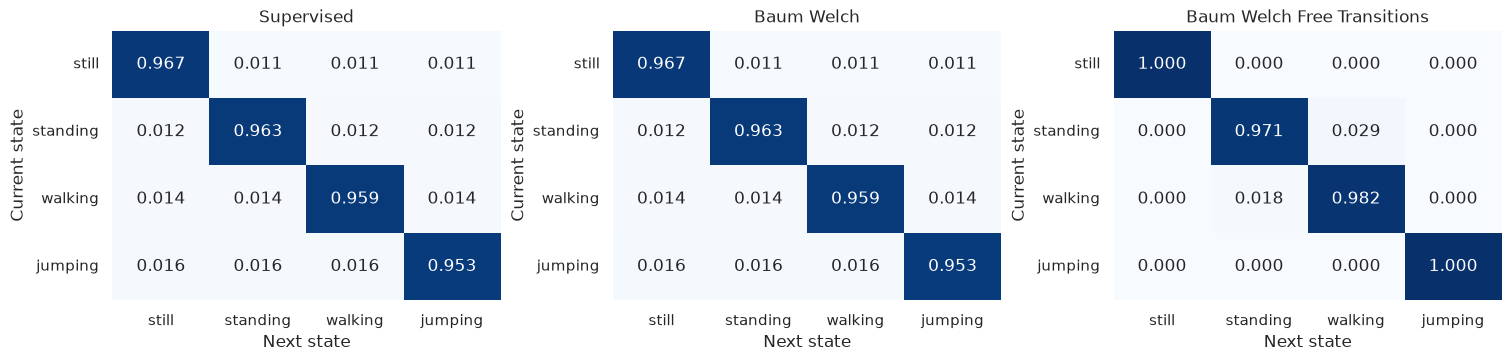

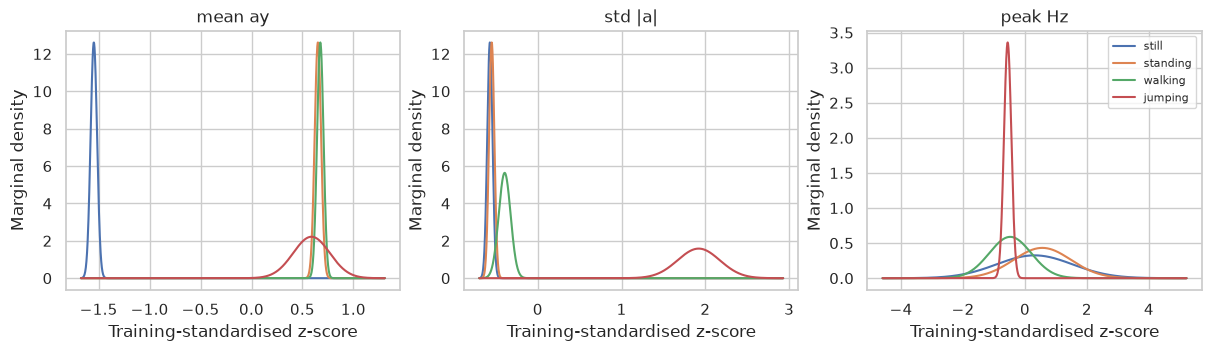

In [32]:
plot_transition_comparison(activity_models)
plt.show()
plot_gaussians(activity_models)
plt.show()

The supervised prior A (left, also the primary model) has diagonals 0.953–0.967:
an activity usually persists from one 1 s step to the next, with a small equal chance
(about 0.011–0.016) of switching to any other activity. With free EM (right), still
and jumping become absorbing (probability 1.000) and only standing↔walking keep small
exits, because the only "switching" EM sees is the standing/walking confusion inside
clips. Neither matrix is learned from real transitions; realistic switching rates need
labelled continuous recordings. The Gaussian curves are one-feature marginals of the
diagonal emission model; narrow peaks reflect small fitted variances.

## 8. Final held-out evaluation

Load the already frozen models and decode **all eight test clips independently**.
No fitting, feature selection, state remapping or model selection occurs here.
Training scores below are resubstitution scores; they are provided only to
contrast fitting-data performance with held-out results. All three predeclared
models are reported, regardless of which performs better.

Metric arithmetic uses NumPy. Rows of the confusion matrix are true activities;
columns are predictions in the fixed order still, standing, walking, jumping.

In [33]:
display(Code(inspect.getsource(confusion_matrix), language="python"))
display(Code(inspect.getsource(metrics_from_confusion), language="python"))
activity_results = evaluate_models(ROOT)
primary_name = activity_results["summary"]["primary_model"]
assert primary_name == "baum_welch"
comparison = activity_results["comparison"]
comparison_view = comparison[["model", "primary", "train_correct", "train_windows", "train_accuracy",
                              "test_correct", "test_windows", "test_accuracy"]].copy()
for column in ["train_accuracy", "test_accuracy"]:
    comparison_view[column] = comparison_view[column].map(lambda value: f"{100*value:.2f}%")
display(comparison_view)

def confusion_matrix(y_true, y_pred, n_states):
    """Count true-label rows and predicted-label columns using NumPy only."""
    true, predicted = np.asarray(y_true), np.asarray(y_pred)
    if (not isinstance(n_states, (int, np.integer)) or n_states < 1
            or true.ndim != 1 or true.shape != predicted.shape or not len(true)
            or not np.issubdtype(true.dtype, np.integer) or not np.issubdtype(predicted.dtype, np.integer)
            or (true < 0).any() or (predicted < 0).any() or (true >= n_states).any() or (predicted >= n_states).any()):
        raise ValueError("Expected aligned nonempty integer labels in [0,N)")
    counts = np.zeros((n_states, n_states), dtype=np.int64)
    np.add.at(counts, (true, predicted), 1)
    return counts

def metrics_from_confusion(matrix, labels):
    """Return metric records, including Overall; count/rate arithmetic is NumPy.

    Per-class accuracy=(TP+TN)/N is one-vs-rest. Overall accuracy=trace(C)/N;
    Overall sensitivity/specificity are macro averages of defined class rates.
    Undefined denominators yield NaN, never a misleading zero or perfect score.
    """
    C = np.asarray(matrix)
    if (C.shape != (len(labels), len(labels)) or not np.issubdtype(C.dtype, np.integer)
            or (C < 0).any() or C.sum() == 0):
        raise ValueError("Expected a nonnegative integer confusion matrix with observations")
    total = int(C.sum())
    support, predicted = C.sum(axis=1), C.sum(axis=0)
    TP = np.diag(C); FN = support-TP; FP = predicted-TP; TN = total-TP-FN-FP
    sensitivity = np.divide(TP, TP+FN, out=np.full(len(labels), np.nan), where=TP+FN > 0)
    specificity = np.divide(TN, TN+FP, out=np.full(len(labels), np.nan), where=TN+FP > 0)
    rows = [{'activity': label, 'n_windows': int(support[i]), 'TP': int(TP[i]), 'FN': int(FN[i]),
             'FP': int(FP[i]), 'TN': int(TN[i]), 'sensitivity': float(sensitivity[i]),
             'specificity': float(specificity[i]), 'accuracy': float((TP[i]+TN[i])/total)}
            for i, label in enumerate(labels)]
    rows.append({'activity': 'Overall', 'n_windows': total, 'TP': None, 'FN': None, 'FP': None, 'TN': None,
                 'sensitivity': float(np.nanmean(sensitivity)) if np.isfinite(sensitivity).any() else float('nan'),
                 'specificity': float(np.nanmean(specificity)) if np.isfinite(specificity).any() else float('nan'),
                 'accuracy': float(np.trace(C)/total)})
    return rows

,model,primary,train_correct,train_windows,train_accuracy,test_correct,test_windows,test_accuracy
0,supervised,False,337,338,99.70%,64,65,98.46%
1,baum_welch,True,336,338,99.41%,63,65,96.92%
2,baum_welch_free_transitions,False,336,338,99.41%,63,65,96.92%
3,gaussian_baseline,False,336,338,99.41%,64,65,98.46%


**Observed comparison:** the supervised HMM and the independent Gaussian baseline
score **64/65 = 98.46%** on test windows. Both Baum–Welch models score **63/65 = 96.92%**
(training 336/338 = 99.41%) with the same two errors: fixing A changes no held-out
prediction, because single-activity clips never require a switch. EM raises the
training likelihood (654.82 → 664.10 with A fixed; → 674.29 with free A) while slightly
reducing accuracy, so higher likelihood did not mean better classification here.
The primary model is retained as stated; nothing is retuned on test scores.

### 8.1 Rubric metrics table

Sensitivity = TP/(TP+FN), specificity = TN/(TN+FP), and each activity's accuracy
= (TP+TN)/N (**one-vs-rest**). The Overall row reports macro sensitivity,
macro specificity and true multiclass accuracy = trace(confusion)/N.
The column heading follows the rubric, but the per-class values include true
negatives and should not be mistaken for that class's recall or headline
multiclass accuracy. Number of Samples means **windows**, not raw sensor rows.

In [34]:
primary_metrics = activity_results["metrics"].query("model == @primary_name and split == 'test'").copy()
primary_confusion = np.array(activity_results["confusion"][primary_name]["test"])
assert primary_confusion.sum() == 65
assert primary_confusion.trace() == 63
assert np.array_equal(primary_confusion.sum(axis=1), primary_metrics.iloc[:4].n_windows.to_numpy())
assert np.isclose(primary_metrics.iloc[-1].accuracy, primary_confusion.trace()/primary_confusion.sum())
report_table = primary_metrics[["activity", "n_windows", "sensitivity", "specificity", "accuracy"]].copy()
report_table.columns = ["State (Activity)", "Number of Samples (windows)", "Sensitivity", "Specificity", "Overall Accuracy"]
for column in ["Sensitivity", "Specificity", "Overall Accuracy"]:
    report_table[column] = report_table[column].map(lambda value: f"{100*value:.2f}%")
display(report_table.set_index("State (Activity)"))
display(primary_metrics[["activity", "TP", "FN", "FP", "TN"]])

,Number of Samples (windows),Sensitivity,Specificity,Overall Accuracy
State (Activity),,,,
still,18,100.00%,100.00%,100.00%
standing,18,88.89%,100.00%,96.92%
walking,18,100.00%,95.74%,96.92%
jumping,11,100.00%,100.00%,100.00%
Overall,65,97.22%,98.94%,96.92%


,activity,TP,FN,FP,TN
15,still,18.0,0.0,0.0,47.0
16,standing,16.0,2.0,0.0,47.0
17,walking,18.0,0.0,2.0,45.0
18,jumping,11.0,0.0,0.0,54.0
19,Overall,NaN,NaN,NaN,NaN


Standing sensitivity is **88.89%** because two standing windows are predicted
as walking. Walking sensitivity remains 100%, but its specificity falls to
**95.74%** due to those false positives. Still and jumping are perfect on their
small held-out samples. The Overall row has **97.22% macro sensitivity**, **98.94%
macro specificity** and **96.92% multiclass accuracy**. The confusion matrix and
overall accuracy are the headline results; high one-vs-rest accuracies partly
reflect numerous true negatives.

### 8.2 Per-clip results and error locations

Each clip retains its own identity and timing. The following tables expose all
eight files and all comparator error counts rather than only pooled metrics.

In [35]:
clip_results = activity_results["per_clip"]
display(clip_results.query("model == @primary_name and split == 'test'")[["sequence_id", "activity", "n_windows", "correct", "errors", "accuracy"]])
display(clip_results.query("split == 'test'").pivot(index=["activity", "sequence_id", "n_windows"], columns="model", values="errors"))
primary_predictions = activity_results["predictions"][primary_name]["test"]
errors = primary_predictions[primary_predictions.true_state != primary_predictions.predicted_state]
display(errors[["sequence_id", "window_index", "start_s", "stop_s", "true_activity", "predicted_activity"]])

,sequence_id,activity,n_windows,correct,errors,accuracy
96,jumping_02,jumping,5,5,0,1.000
97,jumping_07,jumping,6,6,0,1.000
98,standing_06,standing,9,7,2,0.778
99,standing_13,standing,9,9,0,1.000
100,still_02,still,9,9,0,1.000
101,still_11,still,9,9,0,1.000
102,walking_02,walking,9,9,0,1.000
103,walking_10,walking,9,9,0,1.000


model                           baum_welch  baum_welch_free_transitions  \
activity sequence_id n_windows                                            
jumping  jumping_02  5                   0                            0   
         jumping_07  6                   0                            0   
standing standing_06 9                   2                            2   
         standing_13 9                   0                            0   
still    still_02    9                   0                            0   
         still_11    9                   0                            0   
walking  walking_02  9                   0                            0   
         walking_10  9                   0                            0   

model                           gaussian_baseline  supervised  
activity sequence_id n_windows                                 
jumping  jumping_02  5                          0           0  
         jumping_07  6                          0           0  
standing standing_06 9                          1           1  
         standing_13 9                          0           0  
still    still_02    9                          0           0  
         still_11    9                          0           0  
walking  walking_02  9                          0           0  
         walking_10  9                          0           0

,sequence_id,window_index,start_s,stop_s,true_activity,predicted_activity
14,standing_06,3,5.445,7.445,standing,walking
19,standing_06,8,10.445,12.445,standing,walking


Both primary errors are in **standing_06**, windows 3 and 8 (zero-based), at
original-recording intervals [5.445213,7.445213) s and [10.445213,12.445213) s.
The supervised HMM and baseline share only the window-3 error. The other seven
clips have no errors. Window 3 overlaps a local signal fluctuation visible below;
that visual association does not isolate a causal feature. Window 8 is the last
complete window, so there are no future observations to constrain its path.
The retained truth remains standing; predictions do not justify relabelling.
These clips contain no verified cross-activity transitions, so transition-error
rates cannot be reported. Equal weighting per clip gives primary accuracy 97.22%;
the reported 96.92% pools windows and therefore weights longer clips more.

### 8.3 Report figures

All report figures use the **primary model (Baum–Welch, A fixed)**. Figure 2 shows its
parameters; Figure 3 pairs the held-out confusion matrix with the training likelihood;
Figure 4 decodes the continuous session 1 recording (Section 8.4). Each figure is
exported at 180 dpi.

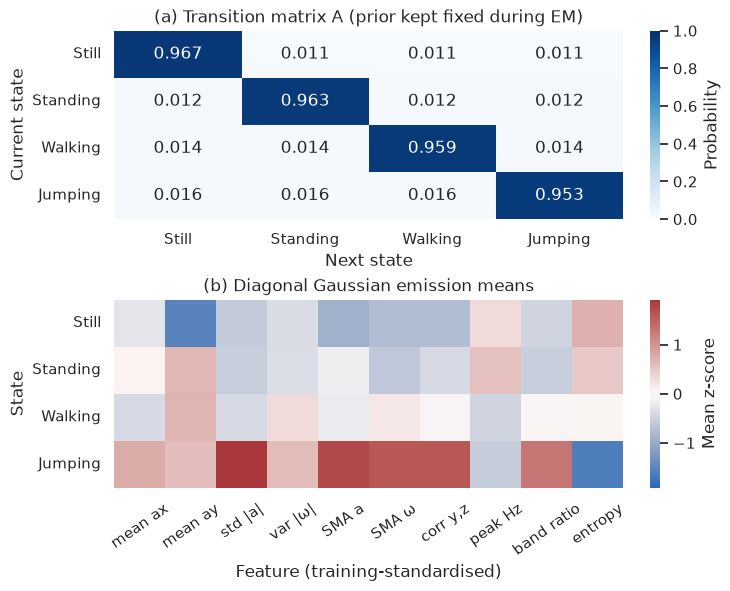

In [36]:
report_figures = generate_figures(ROOT)
plt.close("all")  # Display each saved figure only beneath its matching interpretation.
display(report_figures["fig2_transition_emissions.png"])
plt.close(report_figures["fig2_transition_emissions.png"])

**Figure 2.** Rows of A sum to one; A is the supervised prior kept fixed during EM,
so its strong diagonal encodes persistence rather than learned switching rates.
Emission means are in standardised feature units, not probabilities; the diagonal
variances are illustrated by the marginal curves above. The gravity-orientation cue
(mean acc_y) separates still from the upright activities, and jumping stands out on
every motion-intensity feature.

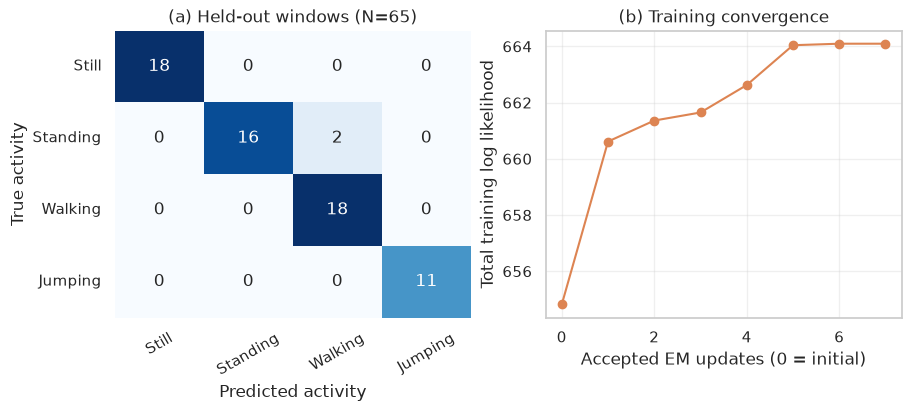

In [37]:
display(report_figures["fig3_confusion_convergence.png"])
plt.close(report_figures["fig3_confusion_convergence.png"])

**Figure 3.** The two errors are standing windows predicted as walking. The likelihood
curve uses training sequences only and stops after update 7, when the improvement
(1.18e-6) falls below the 1e-4 tolerance.

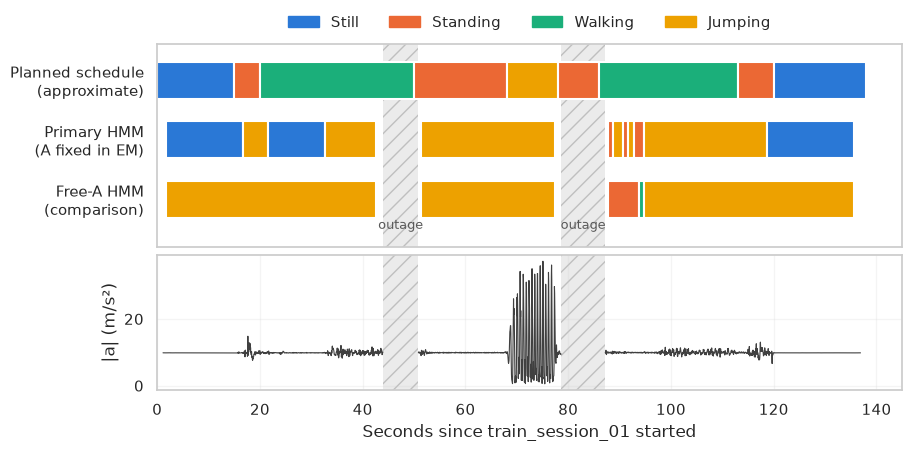

model,baum_welch,baum_welch_free_transitions
sequence_id,,
train_session_01_part01,4,1
train_session_01_part02,1,1
train_session_01_part03,7,3
train_session_02_part01,8,1


model,baum_welch,baum_welch_free_transitions
predicted_activity,,
jumping,83,130
standing,11,6
still,43,0
walking,0,1


In [38]:
display(report_figures["fig4_session_decoding.png"])
plt.close(report_figures["fig4_session_decoding.png"])
session_decoding = decode_sessions(ROOT, activity_models)
runs = (session_decoding.assign(change=lambda d: d.groupby(["model", "sequence_id"]).predicted_activity
                                .transform(lambda s: (s != s.shift()).cumsum()))
        .groupby(["model", "sequence_id", "change"]).agg(activity=("predicted_activity", "first"),
                                                       start_s=("start_s", "first"), windows=("start_s", "size")))
display(runs.groupby(["model", "sequence_id"]).size().rename("decoded runs").unstack(0))
display(session_decoding.groupby(["model", "predicted_activity"]).size().unstack(0).fillna(0).astype(int))

### 8.4 Decoding continuous sessions (Figure 4)

The four recovered session blocks contain real activity changes but no verified labels,
so they give no accuracy figures; they show how each model behaves when switching is
possible. Figure 4 decodes the three blocks of session 1 separately (sensor outages are
hatched and never joined). The planned schedule is the approximate timer protocol, not
verified truth: the |a| trace shows, for example, that walking started near 33 s rather
than 20 s.

- **Free A (comparison):** every window of the first two blocks is decoded as jumping,
  including the long still period at the start. Once in an absorbing state it can never
  leave, so the model is unusable for continuous monitoring.
- **Primary (A fixed):** it leaves states freely. It recognises the still periods at the
  start and end, labels the real jumping burst (about 68–77 s) as jumping, and produces
  genuine predicted transitions (20 decoded runs across the four blocks, against 6 for
  free A, which never predicts still).
- **Remaining error:** most walking and standing in this session are still decoded as
  jumping. The session was recorded with a different grip: its mean acc_y is about
  −0.6 z, against +0.65 z (sd 0.03) for standing and walking clips. These windows lie far
  from every trained state and fall into jumping, the broadest emission (sd 0.18). The
  model therefore depends strongly on phone placement through its orientation features.

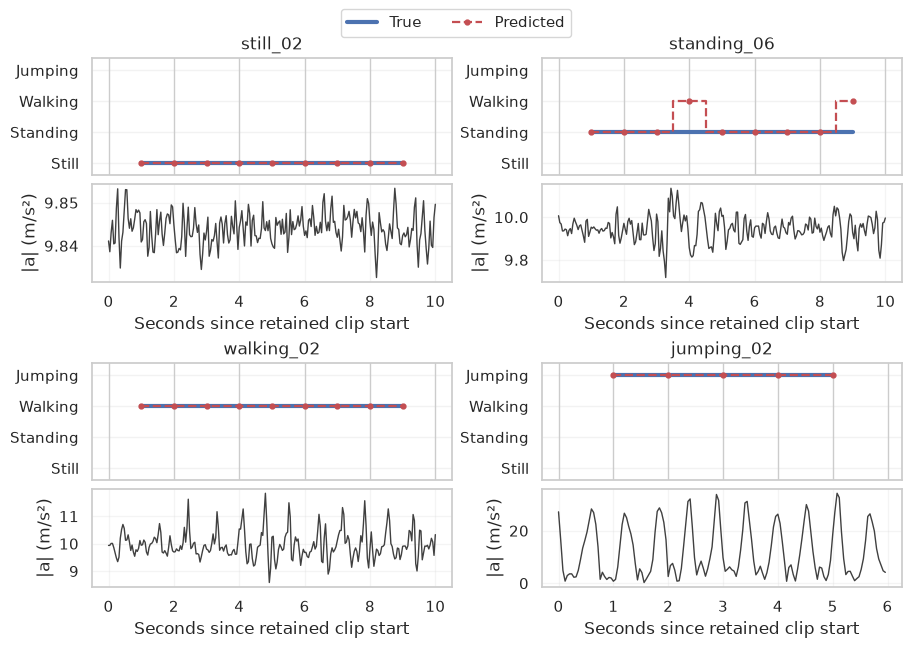

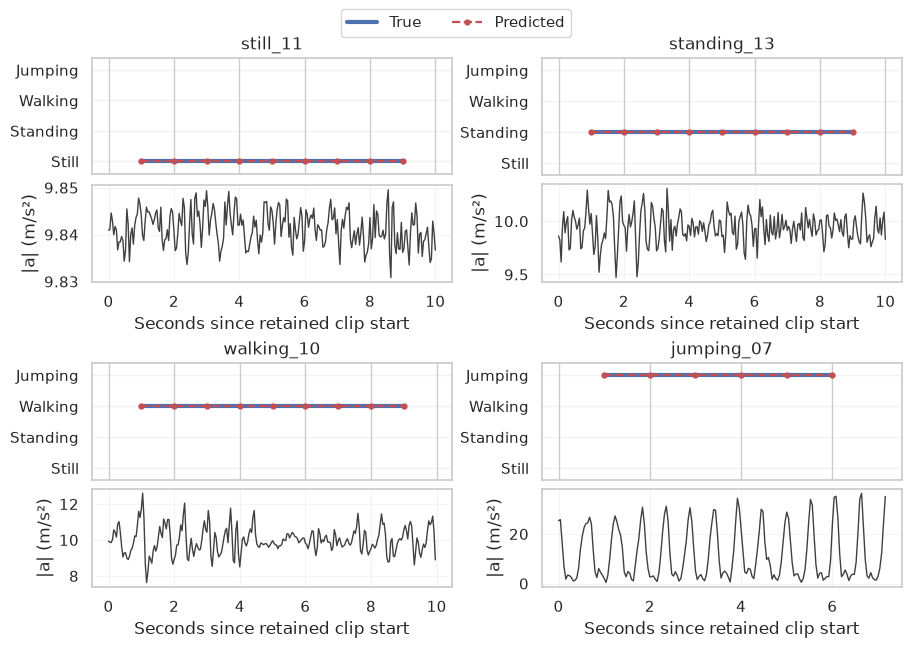

In [39]:
# Notebook only: all eight held-out clips with true and predicted labels.
display(report_figures["test_clip_timelines.png"])
plt.close(report_figures["test_clip_timelines.png"])
remaining_names = ["still_11", "standing_13", "walking_10", "jumping_07"]
plot_timelines(ROOT, activity_models, primary_predictions, remaining_names)
plt.show()

**Held-out clip timelines (notebook only).** Each panel is one independent test clip,
with true and predicted labels at 2 s window centres above processed |a|. Only
standing_06 contains errors (windows 3 and 8); the other seven clips are decoded
perfectly. Time restarts for each clip, and |a| ranges differ between panels.

### 8.5 Generalisation and checkpoint

All eight held-out files were excluded from fitting and mapping. They were inspected and
cropped during quality checks and share the participant, device and collection
conditions with training. The **65 overlapping windows are not 65 independent trials**,
with only two test clips per activity, so no binomial interval is claimed. Training
accuracy is resubstitution, not a validation estimate.

The results support recognition within this collection. Section 8.4 shows the limits
outside it: a change of grip moves the orientation features far from training, and
transition probabilities are a persistence prior rather than learned switching rates.
Performance for a new participant, device, phone position or real falls is untested.

Model and input hashes, mappings, likelihood histories and per-window predictions are
saved under `data/models/` and `data/evaluation/`; re-running this notebook reproduces
them exactly.

In [40]:
assert sum(primary_metrics.iloc[:4].n_windows) == 65
assert len(primary_predictions.sequence_id.unique()) == 8
assert len(errors) == 2
assert activity_results["summary"]["primary_model"] == activity_models["protocol"]["primary_model"]
assert (np.array(activity_models['models'][primary_name]['parameters']['A']) > 0).all()
for name in activity_models["models"]:
    assert np.allclose(aligned_parameters(activity_models, name)["A"].sum(axis=1), 1)
for figure_name in report_figures:
    assert (FIG_DIR / figure_name).is_file()
print("PASS — Phase 7 fixed-model training, comparison, held-out metrics and report figures")
print("Primary (A fixed) and free-A Baum–Welch: 63/65 = 96.92%; supervised and baseline: 64/65 = 98.46%")

PASS — Phase 7 fixed-model training, comparison, held-out metrics and report figures
Primary (A fixed) and free-A Baum–Welch: 63/65 = 96.92%; supervised and baseline: 64/65 = 98.46%
